<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_11_Novelty_and_Outlier_Detection/Chapter_11_Novelty_and_Outlier_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 11 — Novelty and Outlier Detection

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

A model is only as good as the data it is trained on, and real data contains observations that do not fit: a faulty sensor, a typing error, a fraudulent transaction, a machine about to fail. Chapter 11 is about **finding those observations**. The chapter shows how to:

* tell **outliers** (abnormal points that are already in the training data) from **novelties** (abnormal points that appear only after training);
* detect anomalies with the **Local Outlier Factor (LOF)**, **Isolation Forest** and the **One-Class SVM**;
* **evaluate** a detector with a confusion matrix, precision, recall, F1 and the ROC-AUC;
* **handle** the detected points: remove, replace, cap (winsorize) or flag them;
* **choose** a technique from the data: size, dimension, density, availability of clean training data;
* practise with three exercises on synthetic fraud, network and sensor data.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Introduction to outlier and novelty detection | Yes, 2 listings | Which planted outliers can be detected at all, the fixed share forced by `contamination`, the API of outlier and novelty detectors, anomalies inside every marginal range, masking |
| 2 | Understanding Isolation Forest | Yes, 2 listings | The score reproduced from the forest's own trees, path lengths, `contamination` as a threshold, number of trees, invariance to scaling, where the method is blind |
| 3 | One-Class SVM for novelty detection | Yes, 2 listings | Why the book's result looks wrong, the meaning of `nu` and `gamma`, overfitting of the boundary, feature scaling |
| 4 | Detecting outliers with LOF | Yes, 2 listings | LOF by hand, the choice of `n_neighbors`, local against global outliers, `novelty=True` |
| 5 | Evaluating outlier detection models | Yes, 2 listings | The sign of the ROC-AUC, the accuracy trap, ROC and precision-recall curves, the ceiling set by the data, run-to-run variation |
| 6 | Handling detected outliers | Yes, 2 listings | What winsorizing really changes, each strategy tested on a regression, errors against genuine extremes, handling inside a `Pipeline` |
| 7 | Choosing the right detection technique | Yes, 2 listings | The book's comparison table tested row by row: dimension, size, density, clean against contaminated training data, combining detectors |
| 8 | Practical exercises in novelty and outlier detection | Official solutions | Invariance of Isolation Forest to scaling, LOF against Isolation Forest, the effect of `nu` and `gamma` |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

Every dataset in this chapter is generated by NumPy and scikit-learn (`make_blobs`, `make_moons`), so the notebook runs offline. The setup cell prints the library versions, defines the plotting style of the extra figures and two small helpers.

**A note on random numbers.** The book seeds NumPy's *global* generator (`np.random.seed(2024)`) in recipes 1, 2 and 4, and then keeps drawing from that same stream in recipes 3, 5 and 6 and in the exercises (`np.random.uniform(...)` without a seed). The results printed in the book therefore depend on running the cells **in order**. The listings below are reproduced unchanged and in the book's order, so they give the book's numbers. Every extra uses its own generator (`np.random.default_rng(...)`) and passes `random_state` to every estimator, so the extras never touch the global stream and cannot change the results of the listings. One estimator needs care: `OneClassSVM` has no `random_state`, and libsvm draws one number from the global generator each time it is fitted. The extras therefore fit `QuietOneClassSVM`, a two-line subclass defined below that restores the global generator after fitting; the listings use the plain `OneClassSVM`, as in the book.

In [1]:
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from sklearn.svm import OneClassSVM

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {sns.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})


def scatter_flags(ax, X, flagged, title=None, labels=("kept as normal", "flagged"), size=20):
    """Blue circles for the points kept as normal, orange triangles for the flagged ones."""
    flagged = np.asarray(flagged, dtype=bool)
    ax.scatter(X[~flagged, 0], X[~flagged, 1], s=size, color=PALETTE[0], marker="o", alpha=0.7, label=f"{labels[0]} ({(~flagged).sum()})")
    ax.scatter(X[flagged, 0], X[flagged, 1], s=size * 2, color=PALETTE[1], marker="^", label=f"{labels[1]} ({flagged.sum()})")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    if title:
        ax.set_title(title)
    ax.legend(loc="best", fontsize=8)


class QuietOneClassSVM(OneClassSVM):
    """OneClassSVM that leaves NumPy's global random generator as it found it.

    libsvm draws one number from the global generator every time a One-Class SVM is fitted (the class has no random_state).
    The extras fit this subclass so that they never move the global stream that the book's listings depend on.
    """

    def fit(self, X, y=None, sample_weight=None):
        state = np.random.get_state()
        try:
            return super().fit(X, y, sample_weight=sample_weight)
        finally:
            np.random.set_state(state)


def rank_of(scores, index):
    """Rank of one sample when the samples are sorted from the most to the least abnormal (1 = most abnormal)."""
    return int((scores > scores[index]).sum()) + 1

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2
seaborn      : 0.13.2


---
## 1. Introduction to outlier and novelty detection

*Book: pp. 280–284.*

### Summary

* **Getting ready** — a synthetic dataset: `make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)` gives 300 normal points, and 20 points drawn uniformly in $[-6, 6]^2$ play the outliers. The seed `np.random.seed(2024)` is set just before the uniform draw. Figure 11.1 shows a dense cluster with a few red points far away.
* **How to do it** — `LocalOutlierFactor(n_neighbors=20, contamination=0.05)` and `fit_predict(X_with_outliers)`; label `1` is an inlier, `-1` an outlier. Figure 11.2 colours the inliers blue and the outliers red.
* **How it works** — detectors estimate whether each point deviates from the expected distribution. **Outliers** can be in the training data and in the test data; **novelties** appear only in the test data. Some models handle one or the other (`IsolationForest()` supports both; `OneClassSVM()` is typically used for novelty detection). `contamination` is the proportion of outliers and calibrates the decision boundary. LOF compares the density of each point with that of its neighbours.
* **There's more** — rules and domain knowledge complement statistical models; detection is sensitive to feature scaling (standardize); in production, novelty detection catches concept drift.
* **Hands-on exercises** — an 8-step workflow: generate data with noise, visualize, use `LocalOutlierFactor()` or `IsolationForest()`, fit and use `predict` or `decision_function`, colour the points, vary `contamination`, compare algorithms.

### Theory

**Anomaly, outlier, novelty.** Hawkins (1980) defines an outlier as *an observation which deviates so much from the other observations as to arouse suspicions that it was generated by a different mechanism*. The two words used in scikit-learn's documentation describe two different situations:

| | Outlier detection | Novelty detection |
|---|---|---|
| Training data | contains abnormal points, unlabelled | assumed to be clean |
| Question | which training points are abnormal? | does a new point come from the training distribution? |
| Learning setting | unsupervised | semi-supervised (only the normal class is known) |
| Typical calls | `fit_predict(X)` | `fit(X_train)`, then `predict(X_new)` |
| Estimators | `LocalOutlierFactor` (default), `IsolationForest`, `EllipticEnvelope` | `OneClassSVM`, `LocalOutlierFactor(novelty=True)`, `IsolationForest` |

**Where anomalies come from, and their kinds.** A point can be abnormal because of an *error* (a faulty sensor, a typing mistake), because of a *rare but genuine event* (a fraud, a failing machine) or because it belongs to *another population*. The treatment of the point depends on which one it is (recipe 6). By structure, Chandola, Banerjee and Kumar (2009) distinguish **point** anomalies (a single point far from the rest), **contextual** anomalies (a value that is normal in general but abnormal in its context, such as 30 °C in January) and **collective** anomalies (a group of points that are normal one by one but abnormal together, such as a flat segment in a heartbeat signal). The detectors of this chapter look at points in a feature space, so contextual and collective anomalies must be turned into features first.

**The scikit-learn conventions.** All detectors of the library follow the same vocabulary:

* `predict(X)` returns **+1 for inliers and −1 for outliers**. This is *not* the 0/1 coding of the metrics of recipe 5, so a conversion is needed.
* `decision_function(X)` is a score where **negative means outlier and positive means inlier**; `score_samples(X)` is the raw score (lower is more abnormal) and
$$\text{decision\_function}(x) = \text{score\_samples}(x) - \text{offset\_}.$$
* `contamination` is the expected share of outliers. It does not change the scores: it only sets `offset_`, the threshold, as the corresponding percentile of the training scores. With `contamination='auto'` the threshold is fixed by the method (−0.5 for Isolation Forest, −1.5 for LOF; the One-Class SVM uses `nu` instead).

**Two classical difficulties.**

* *Masking and swamping.* A group of outliers inflates the mean and the standard deviation, so that the outliers look normal (masking) and genuine points look abnormal (swamping). The classical rule "flag $|z| > 3$" with $z = (x - \bar{x}) / s$ fails in this situation. Robust statistics replace the mean by the median and the standard deviation by $1.4826 \times \text{MAD}$, where $\text{MAD} = \operatorname{median}|x_i - \operatorname{median}(x)|$ (the factor makes it consistent with the standard deviation of a normal distribution); Iglewicz and Hoaglin (1993) flag a modified $z$-score above 3.5.
* *Abnormal as a whole, normal in each coordinate.* In several dimensions a point can be inside the range of every feature and still be far from the data, because features are correlated. The right distance is the **Mahalanobis distance**
$$d_M(x) = \sqrt{(x - \mu)^\top \Sigma^{-1} (x - \mu)},$$
which accounts for the covariance $\Sigma$. For Gaussian data $d_M^2$ follows a $\chi^2$ distribution with $d$ degrees of freedom, which gives a threshold. `EllipticEnvelope` estimates $\mu$ and $\Sigma$ robustly (Minimum Covariance Determinant, Rousseeuw and Driessen, 1999) so that the outliers do not distort them.

**Families of detectors.** *Statistical* (Mahalanobis, `EllipticEnvelope`), *proximity and density* (distance to neighbours, LOF), *boundary* (One-Class SVM) and *isolation* (Isolation Forest). The next recipes take one of each, except the statistical family, which appears as a baseline.

### Book code

The two listings below are the book's *Getting ready* and *How to do it* steps (pp. 280–283). The book's variable `X_with_outliers` stacks the 300 normal points and the 20 planted ones.

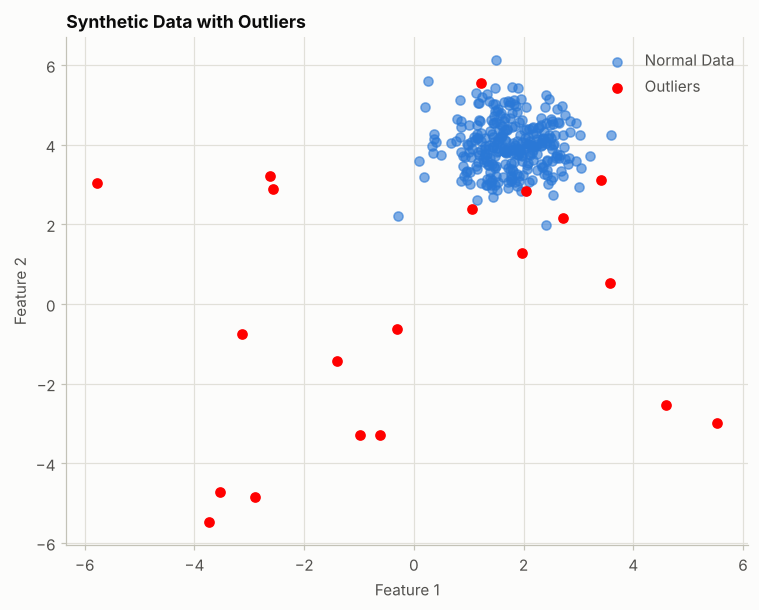

In [2]:
# BOOK CODE (pp. 280-281): load the libraries, generate a dataset with intentional outliers and visualize it
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate a synthetic dataset with intentional outliers
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.60, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualize the data with outliers
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

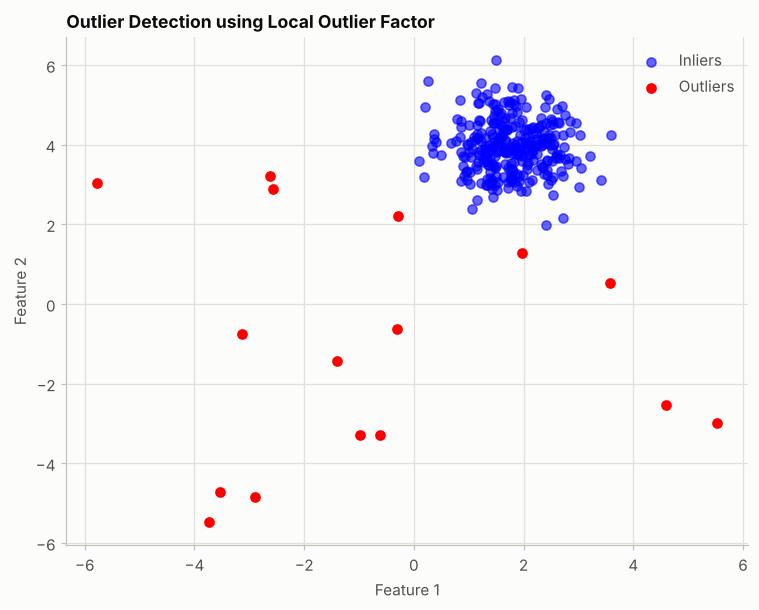

In [3]:
# BOOK CODE (pp. 282-283): Local Outlier Factor
# Load the model
from sklearn.neighbors import LocalOutlierFactor

# Fit the model and predict outliers
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Local Outlier Factor")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Output analysis.**

* The first listing prints nothing. Figure 11.1 shows a dense cluster of 300 points around $(1.8, 4.0)$ (with `centers=1`, `make_blobs` draws the centre at random in $[-10, 10]^2$, so the cluster is not at the origin) and 20 points spread uniformly over $[-6, 6]^2$. Most of them are visibly far away; a few sit inside or against the cluster.
* The second listing flags **16 points**: 15 of the 20 planted points and 1 normal point. The number 16 is not a finding: it is 5% of 320 points, the `contamination` that was requested. Figure 11.2 colours them red. Extra (a) shows that the 5 planted points that were *not* flagged cannot be told from the normal data at all.

### Extra experiments

**(a) Which planted points can be detected at all?** The generator is known: the normal points have a standard deviation of 0.60 around their centre, so 99.9% of them lie within $\sqrt{\chi^2_{2,\,0.999}} = 3.72$ standard deviations of it. A planted point that falls closer than that is statistically indistinguishable from the normal data, whatever the detector. The cell lists the planted points by their distance to the blob centre, in standard deviations, and marks the ones LOF flagged.

 distance (sd)  inside the 99.9% disc  flagged by LOF
          1.98                   True           False
          2.75                   True           False
          2.90                   True           False
          3.12                   True           False
          3.45                   True           False
          4.51                  False            True
          6.50                  False            True
          7.40                  False            True
          7.44                  False            True
          8.41                  False            True
         10.43                  False            True
         11.34                  False            True
         11.84                  False            True
         12.65                  False            True
         12.75                  False            True
         12.95                  False            True
         13.19                  False            True
         16.65              

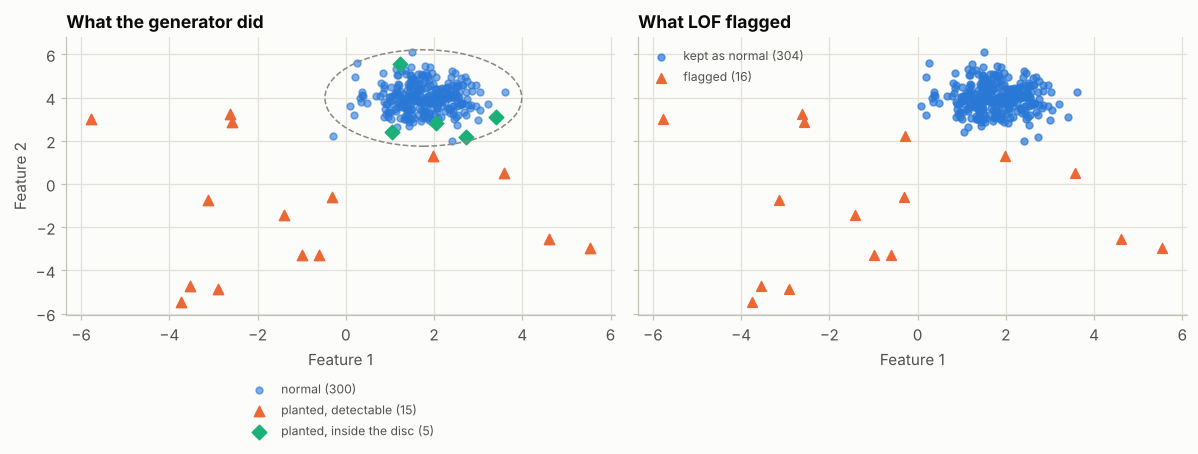

In [4]:
# EXTRA (a): the planted points that sit inside the blob cannot be told apart from it
from scipy.stats import chi2

centre, sigma = X.mean(axis=0), 0.60                       # cluster_std of the generator
limit = np.sqrt(chi2.ppf(0.999, df=2))                      # radius holding 99.9 % of a 2-D Gaussian, in standard deviations
dist_sd = np.linalg.norm(outliers - centre, axis=1) / sigma
hidden = dist_sd < limit
flagged_by_lof = y_pred[300:] == -1

table = pd.DataFrame({"distance (sd)": dist_sd.round(2), "inside the 99.9% disc": hidden, "flagged by LOF": flagged_by_lof}).sort_values("distance (sd)")
print(table.to_string(index=False))
print(f"\nradius of the 99.9% disc: {limit:.2f} standard deviations")
print(f"planted points inside the disc : {hidden.sum()} of 20 (they look like normal data)")
print(f"planted points flagged by LOF  : {flagged_by_lof.sum()} of 20; normal points flagged: {(y_pred[:300] == -1).sum()} of 300")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
ax = axes[0]
ax.scatter(X[:, 0], X[:, 1], s=20, color=PALETTE[0], marker="o", alpha=0.6, label="normal (300)")
ax.scatter(outliers[~hidden, 0], outliers[~hidden, 1], s=45, color=PALETTE[1], marker="^", label=f"planted, detectable ({(~hidden).sum()})")
ax.scatter(outliers[hidden, 0], outliers[hidden, 1], s=45, color=PALETTE[2], marker="D", label=f"planted, inside the disc ({hidden.sum()})")
ax.add_patch(plt.Circle(centre, limit * sigma, fill=False, ls="--", color=MUTED))
ax.set_title("What the generator did")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=8)
scatter_flags(axes[1], X_with_outliers, y_pred == -1, title="What LOF flagged")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**(b) `contamination` fixes the share of flagged points.** The parameter is not an estimate learned from the data: the detector flags exactly that share of the training points. The cell fits LOF and Isolation Forest on 300 points drawn from a single Gaussian, with **no outlier at all**, for three values of `contamination` and for `'auto'`.

In [5]:
# EXTRA (b): contamination forces a share of flagged points, even on clean data
from sklearn.ensemble import IsolationForest

clean = np.random.default_rng(0).normal(size=(300, 2))     # no outlier at all
rows = []
for c in [0.01, 0.05, 0.10, "auto"]:
    n_lof = (LocalOutlierFactor(n_neighbors=20, contamination=c).fit_predict(clean) == -1).sum()
    n_if = (IsolationForest(contamination=c, random_state=0).fit_predict(clean) == -1).sum()
    rows.append({"contamination": c, "requested share of 300": "—" if c == "auto" else f"{c * 300:.0f}", "LOF flags": n_lof, "Isolation Forest flags": n_if})
print("Clean Gaussian data, 300 points, no outlier:")
print(pd.DataFrame(rows).set_index("contamination").to_string())

Clean Gaussian data, 300 points, no outlier:
              requested share of 300  LOF flags  Isolation Forest flags
contamination                                                          
0.01                               3          3                       3
0.05                              15         15                      15
0.1                               30         30                      30
auto                               —         17                      47


**(c) The API of detectors.** Which methods does each detector offer? The table is computed by asking the *fitted* objects.

In [6]:
# EXTRA (c): which methods does each detector offer?
from sklearn.covariance import EllipticEnvelope
from sklearn.svm import OneClassSVM

fit_data = np.random.default_rng(0).normal(size=(200, 2))
detectors = {
    "LocalOutlierFactor()": LocalOutlierFactor(),
    "LocalOutlierFactor(novelty=True)": LocalOutlierFactor(novelty=True),
    "IsolationForest()": IsolationForest(random_state=0),
    "OneClassSVM()": QuietOneClassSVM(),
    "EllipticEnvelope()": EllipticEnvelope(random_state=0),
}
methods = ["fit_predict", "predict", "decision_function", "score_samples"]
rows = {}
for name, detector in detectors.items():
    detector.fit(fit_data)
    rows[name] = {m: "yes" if hasattr(detector, m) else "no" for m in methods}
print(pd.DataFrame(rows).T.to_string())

                                 fit_predict predict decision_function score_samples
LocalOutlierFactor()                     yes      no                no            no
LocalOutlierFactor(novelty=True)          no     yes               yes           yes
IsolationForest()                        yes     yes               yes           yes
OneClassSVM()                            yes     yes               yes           yes
EllipticEnvelope()                       yes     yes               yes           yes


**(d) A point can be normal in every coordinate and abnormal as a whole.** Two features with a correlation of 0.9, 300 points, and one extra point at $(2, -2)$. Each coordinate of that point is only about 2 standard deviations from its mean, but it contradicts the correlation. The cell compares the per-feature rule, the Mahalanobis distance and the four detectors (rank 1 = the most abnormal of the 301 points).

per-feature z-scores of the point : [ 2.   -2.02]  -> both below 3, so the univariate rule keeps it
Mahalanobis distance of the point : 9.33  (99.9% limit under a Gaussian: 3.72)

Rank of the point among the 301 (1 = most abnormal):
  Isolation Forest  :   1
  LOF (k=20)        :   1
  One-Class SVM     :   1
  Elliptic Envelope :   1


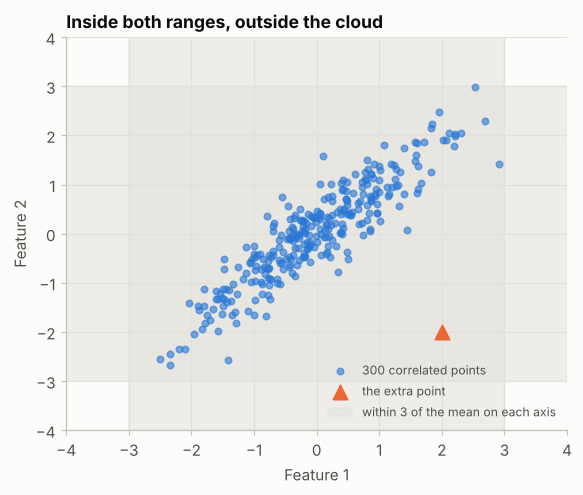

In [7]:
# EXTRA (d): marginal ranges against the joint structure
rng = np.random.default_rng(3)
correlated = rng.multivariate_normal([0, 0], [[1, 0.9], [0.9, 1]], size=300)
point = np.array([[2.0, -2.0]])
data_d = np.vstack([correlated, point])
idx = 300                                                    # position of the planted point

z = (point - correlated.mean(axis=0)) / correlated.std(axis=0)
print(f"per-feature z-scores of the point : {z.round(2).ravel()}  -> both below 3, so the univariate rule keeps it")

mu_d, cov_d = correlated.mean(axis=0), np.cov(correlated.T)
diff = point[0] - mu_d
d_m = np.sqrt(diff @ np.linalg.inv(cov_d) @ diff)
print(f"Mahalanobis distance of the point : {d_m:.2f}  (99.9% limit under a Gaussian: {np.sqrt(chi2.ppf(0.999, 2)):.2f})")

scores_d = {
    "Isolation Forest": -IsolationForest(random_state=0).fit(data_d).score_samples(data_d),
    "LOF (k=20)": -LocalOutlierFactor(n_neighbors=20).fit(data_d).negative_outlier_factor_,
    "One-Class SVM": -QuietOneClassSVM(gamma="scale", nu=0.05).fit(data_d).decision_function(data_d),
    "Elliptic Envelope": -EllipticEnvelope(random_state=0).fit(data_d).decision_function(data_d),
}
print("\nRank of the point among the 301 (1 = most abnormal):")
for name, s in scores_d.items():
    print(f"  {name:18s}: {rank_of(s, idx):3d}")

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.scatter(correlated[:, 0], correlated[:, 1], s=18, color=PALETTE[0], alpha=0.6, label="300 correlated points")
ax.scatter(point[:, 0], point[:, 1], s=90, color=PALETTE[1], marker="^", label="the extra point")
ax.axvspan(-3, 3, color=GRID, alpha=0.5, zorder=0, label="within 3 of the mean on each axis")
ax.axhspan(-3, 3, color=GRID, alpha=0.5, zorder=0)
ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Inside both ranges, outside the cloud")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**(e) Masking.** One feature, 100 values from $N(0, 1)$ and 40 abnormal values around 8 (29% of the data). The classical $z$-score and the robust modified $z$-score are compared.

In [8]:
# EXTRA (e): masking - a large group of outliers hides itself from the mean and the standard deviation
rng = np.random.default_rng(1)
normal_part, abnormal_part = rng.normal(0, 1, 100), rng.normal(8, 0.5, 40)
v = np.r_[normal_part, abnormal_part]
truth = np.r_[np.zeros(100, bool), np.ones(40, bool)]

z_classic = (v - v.mean()) / v.std()
med = np.median(v)
mad = np.median(np.abs(v - med)) * 1.4826
z_robust = (v - med) / mad

print(f"mean {v.mean():.2f}, std {v.std():.2f}     (the 100 normal values alone: {normal_part.mean():.2f}, {normal_part.std():.2f})")
print(f"median {med:.2f}, scaled MAD {mad:.2f}\n")
for name, flag in [("classical |z| > 3", np.abs(z_classic) > 3), ("robust |z| > 3.5", np.abs(z_robust) > 3.5)]:
    print(f"{name:20s}: flags {flag.sum():3d} values, {(flag & truth).sum():2d} of the 40 abnormal ones, {(flag & ~truth).sum()} normal ones")

mean 2.22, std 3.70     (the 100 normal values alone: -0.07, 0.85)
median 0.34, scaled MAD 1.25

classical |z| > 3   : flags   0 values,  0 of the 40 abnormal ones, 0 normal ones
robust |z| > 3.5    : flags  40 values, 40 of the 40 abnormal ones, 0 normal ones


**Analysis of the extras.**

* **(a)** Five of the 20 planted points lie inside the 99.9% disc, between **1.98 and 3.45 standard deviations** from the centre of the blob: statistically they are normal points, whatever the detector. LOF flagged exactly the **15 other** planted points, plus one normal point, so it found every detectable outlier with a precision of 15 out of 16. No detector can do better on this sample, which is why a recall of 75% is a good result here (recipe 5 comes back to this ceiling).
* **(b)** `contamination` is a **quota**, not an estimate. On 300 points with no outlier at all, LOF and Isolation Forest flag exactly 3, 15 and 30 points for `contamination` of 0.01, 0.05 and 0.10. With `'auto'` the number is not controlled either: LOF flags 17 points and Isolation Forest **47** (16% of clean data). The share of flagged points says nothing about the share of outliers; choose `contamination` from knowledge of the problem, or work with the scores.
* **(c)** The default LOF offers only `fit_predict`. With `novelty=True` it offers `predict`, `decision_function` and `score_samples` and loses `fit_predict`. Isolation Forest, the One-Class SVM and `EllipticEnvelope` offer all four. This is the API behind the outlier/novelty distinction of the theory table, and it will matter when the book says that LOF "cannot predict" (recipe 4).
* **(d)** The extra point has per-feature $z$-scores of 2.00 and $-2.02$, below 3, so a rule applied to each feature keeps it. Its Mahalanobis distance is **9.33**, against a 99.9% limit of 3.72, and all four detectors rank it **first** among the 301 points. In several dimensions "abnormal" is a statement about the joint structure of the features.
* **(e)** With 40 abnormal values among 140 (29%), the mean (2.22) and the standard deviation (3.70) are dominated by them: the 100 normal values alone have $-0.07$ and 0.85. The classical rule flags **0 of the 40**; the robust rule (median 0.34, scaled MAD 1.25) flags all 40 and no normal value. This is masking.

**Where this goes next.** Recipe 1 used LOF only to show the idea. Recipes 2, 3 and 4 take the three detectors of the chapter one by one.

---
## 2. Understanding Isolation Forest

*Book: pp. 284–288.*

### Summary

* **Getting ready** — the same synthetic data as recipe 1 (300 normal points from `make_blobs`, 20 uniform outliers, `np.random.seed(2024)`), stacked into `X_combined` (Figure 11.3). The book adds a remark: data does not have to lie *outside* the distribution to be anomalous; inliers can signal abnormalities too.
* **How to do it** — `IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)`, `fit` and `predict`; Figure 11.4 colours the inliers blue and the outliers red.
* **How it works** — *random splitting* (a random feature and a random split value at each node, so anomalies are isolated in fewer splits), *path length* (the score is the average path length over the trees; short paths mean outliers) and *contamination* (the expected share of outliers, which sets the threshold). Because it uses neither distances nor densities, the book says it performs well in high dimension and scales to large samples.
* **There's more** — feature scaling matters less than for distance-based methods but may still help; `decision_function()` gives continuous scores for ranking and threshold tuning; the model is not incremental but can be retrained on batches.
* **Hands-on exercises** — an 8-step workflow, ending with the use of `decision_function()` to rank samples by anomaly score.

### Theory

**The idea.** Most detectors build a model of what is *normal* and measure the distance to it. Liu, Ting and Zhou (2008) do the opposite: they measure how easy a point is to **isolate**. Anomalies are *few and different*, so a sequence of random cuts of the space separates them from the rest after very few cuts, whereas a point in the middle of a dense cloud needs many.

**Isolation tree.** Take a random subsample $S$ of $\psi$ points. A node cuts $S$ in two:

1. choose a feature $q$ uniformly at random;
2. choose a threshold $p$ uniformly between the minimum and the maximum of feature $q$ in $S$;
3. send the points with $x_q < p$ to the left child and the others to the right child;
4. repeat on each child until the child holds one point or the depth limit $\lceil \log_2 \psi \rceil$ is reached.

The **path length** $h(x)$ is the number of edges from the root to the leaf where $x$ ends. When a leaf still holds $n > 1$ points (the depth limit was reached), the unfinished part of the tree is accounted for by adding $c(n)$, the average path length of an *unsuccessful search* in a binary search tree of $n$ points:

$$c(n) = 2H(n-1) - \frac{2(n-1)}{n}, \qquad H(i) \approx \ln i + \gamma, \qquad \gamma = 0.5772\ldots \text{ (Euler's constant)}.$$

**Anomaly score.** The forest averages $h(x)$ over its $t$ trees and normalizes by $c(\psi)$:

$$s(x, \psi) = 2^{-\,E[h(x)] / c(\psi)}.$$

If $E[h(x)] = c(\psi)$ the score is 0.5 (a "typical" point); if $E[h(x)] \to 0$ the score tends to 1 (certainly anomalous); if $E[h(x)] \to \psi - 1$ it tends to 0 (certainly normal). scikit-learn returns the **opposite**, $-s$, from `score_samples` (so that lower means more abnormal, like the other detectors), and `decision_function = score_samples - offset_`.

**Why subsample.** Each tree sees only $\psi = \min(256, n)$ points by default. A small sample reduces *swamping* (normal points near anomalies are not hidden by them) and *masking*, and makes a tree cheap: training costs $O(t\,\psi \log \psi)$, which does not grow with $n$, and scoring $n$ points costs $O(n\,t \log \psi)$.

**What the method cannot do.**

* The cuts are *axis-parallel* and the feature is drawn at random, so the method needs **informative features**: cuts on irrelevant features are wasted (this is tested in recipe 7).
* It has **no notion of local density**: it compares each point with the whole sample.
* The score map has axis-aligned artefacts, and a point in an empty region that is "between" the marginal ranges of the data can look normal. The Extended Isolation Forest (Hariri, Carrasco Kind and Brunner, 2021) uses random hyperplanes instead; it is not in scikit-learn.

**Invariance to scaling.** Thresholds are drawn uniformly between the minimum and the maximum of a feature. If a feature is replaced by $a x + b$ with $a > 0$ (standardization, a change of units), every threshold moves in the same way, the same points go left and right, and the trees and scores are unchanged. The book's advice that "normalizing features may still improve results" is therefore not true for such transformations; the extras check it.

### Book code

The data (pp. 285–286) is built exactly as in recipe 1, which is why Figure 11.3 repeats Figure 11.1; the model and its figure are on pp. 286–287.

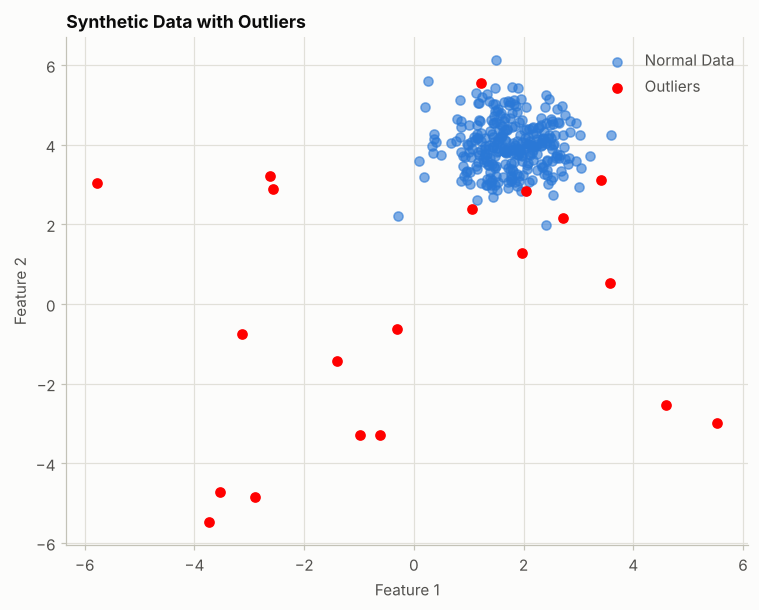

In [9]:
# BOOK CODE (p. 285): load the libraries, generate synthetic data with outliers and visualize it
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Generate synthetic data with outliers
X, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=6, size=(20, 2))
X_combined = np.vstack([X, outliers])

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Normal Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

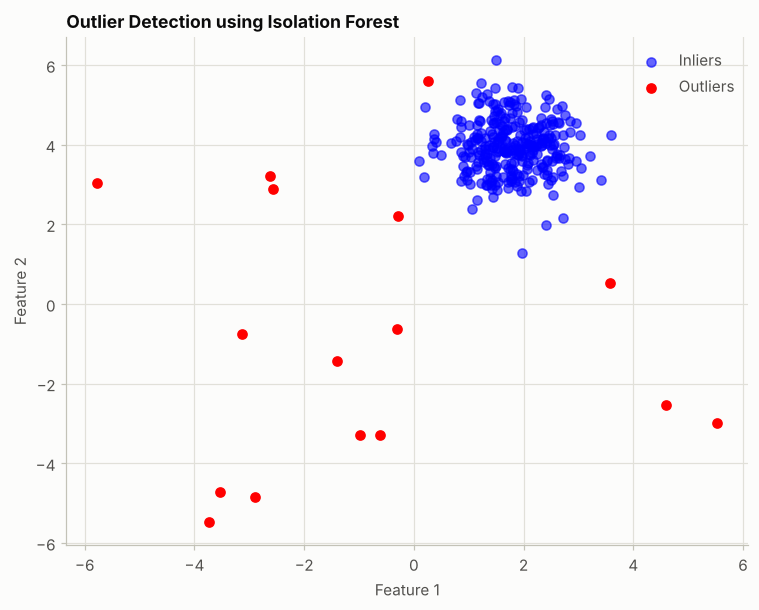

In [10]:
# BOOK CODE (pp. 286-287): Isolation Forest
# Load and configure the model
model = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024)

# Fit the model and make predictions
model.fit(X_combined)
y_pred = model.predict(X_combined)

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X_combined[y_pred == 1, 0], X_combined[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_combined[y_pred == -1, 0], X_combined[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Outlier Detection using Isolation Forest")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Output analysis.**

* Figure 11.3 repeats Figure 11.1: the data is generated with the same seeds. Isolation Forest then flags **16 points**, again exactly 5% of 320: **14 of the 20 planted points and 2 normal points**. The 6 planted points it misses are the 5 that lie inside the normal cloud (recipe 1(a)) and one more, at 4.5 standard deviations from the centre.
* The book remarks that data does not have to lie outside the distribution to be anomalous. The extras show a case where an empty region *inside* the range of every feature is scored as less abnormal by Isolation Forest than by LOF (extra (f)).

### Extra experiments

**(a) The score rebuilt from the trees.** The fitted forest keeps its trees in `estimators_`. The cell computes $h(x)$ itself — the depth of the leaf plus $c(\text{leaf size})$ — averages it over the 100 trees, applies $-2^{-E[h]/c(\psi)}$, and compares the result with `score_samples`. It also checks the statement that `contamination` only sets the threshold `offset_`.

In [11]:
# EXTRA (a): the anomaly score of scikit-learn rebuilt from its own trees
def average_path_length(n):
    """c(n): average path length of an unsuccessful search in a binary search tree of n points."""
    n = np.asarray(n, dtype=float)
    c = np.zeros_like(n)
    c[n == 2] = 1.0
    big = n > 2
    c[big] = 2.0 * (np.log(n[big] - 1.0) + np.euler_gamma) - 2.0 * (n[big] - 1.0) / n[big]
    return c


def path_lengths(forest, data):
    """h(x) for every tree: depth of the leaf holding x, plus c(number of training points in that leaf). Shape: (trees, samples)."""
    out = np.zeros((len(forest.estimators_), len(data)))
    for i, (tree, features) in enumerate(zip(forest.estimators_, forest.estimators_features_)):
        t = tree.tree_
        depth = np.zeros(t.node_count, dtype=int)
        for node in range(t.node_count):                    # a parent always has a smaller index than its children
            if t.children_left[node] != -1:
                depth[t.children_left[node]] = depth[t.children_right[node]] = depth[node] + 1
        leaf = tree.apply(data[:, features])
        out[i] = depth[leaf] + average_path_length(t.n_node_samples[leaf])
    return out


psi = model.max_samples_
paths = path_lengths(model, X_combined)
score_by_hand = -(2.0 ** (-paths.mean(axis=0) / average_path_length([psi])[0]))

print(f"subsample size psi = {psi}, depth limit = {int(np.ceil(np.log2(psi)))}, c(psi) = {average_path_length([psi])[0]:.3f}")
print(f"largest difference between the score by hand and score_samples : {np.abs(score_by_hand - model.score_samples(X_combined)).max():.1e}")
print(f"offset_ = {model.offset_:.4f}; 5th percentile of the training scores = {np.percentile(model.score_samples(X_combined), 5):.4f}")
rule = np.where(model.score_samples(X_combined) < model.offset_, -1, 1)
print(f"predict() equals 'score_samples < offset_' for all {len(rule)} points : {bool((rule == model.predict(X_combined)).all())}")
print(f"decision_function = score_samples - offset_ : {bool(np.allclose(model.decision_function(X_combined), model.score_samples(X_combined) - model.offset_))}")
print(f"mean path length: normal points {paths.mean(axis=0)[:300].mean():.2f}, planted outliers {paths.mean(axis=0)[300:].mean():.2f}")

subsample size psi = 256, depth limit = 8, c(psi) = 10.245
largest difference between the score by hand and score_samples : 1.7e-16
offset_ = -0.5912; 5th percentile of the training scores = -0.5912
predict() equals 'score_samples < offset_' for all 320 points : True
decision_function = score_samples - offset_ : True
mean path length: normal points 13.66, planted outliers 6.51


**(b) Isolation, literally.** The first cell below plays the isolation game with no tree at all: cut the data at a random threshold of a random feature, keep the side that holds the point, and count the cuts until it is alone. It does so 2,000 times for the point closest to the centre of the blob and for the planted point farthest from it. The right panel shows, for the same two points, the path length in each of the 100 trees of the forest.

closest to the centre    : mean 16.71 cuts, 5th-95th percentile 11 to 23
farthest planted outlier : mean  4.34 cuts, 5th-95th percentile 2 to 7


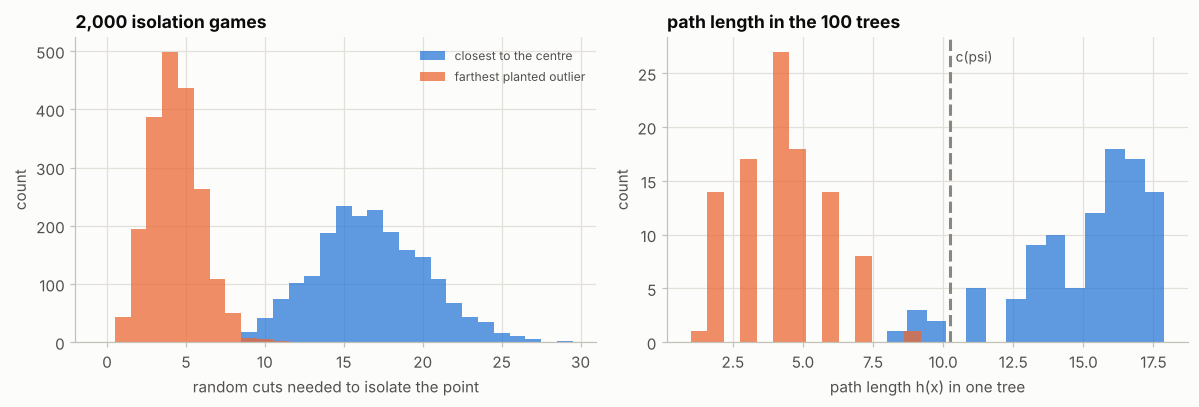

In [12]:
# EXTRA (b): number of random cuts needed to isolate a point, and the path length of that point in each tree
def cuts_to_isolate(x, data, rng):
    """Cut the data at random until the point x is alone; return the number of cuts."""
    current, cuts = data, 0
    while len(current) > 1:
        j = rng.integers(data.shape[1])
        low, high = current[:, j].min(), current[:, j].max()
        if low == high:
            break
        threshold = rng.uniform(low, high)
        current = current[current[:, j] < threshold] if x[j] < threshold else current[current[:, j] >= threshold]
        cuts += 1
    return cuts


rng = np.random.default_rng(0)
centre_of_blob = X.mean(axis=0)
i_inlier = int(np.argmin(np.linalg.norm(X_combined - centre_of_blob, axis=1)))
i_outlier = 300 + int(np.argmax(np.linalg.norm(outliers - centre_of_blob, axis=1)))
cuts = {name: np.array([cuts_to_isolate(X_combined[i], X_combined, rng) for _ in range(2000)]) for name, i in [("closest to the centre", i_inlier), ("farthest planted outlier", i_outlier)]}
for name, c in cuts.items():
    print(f"{name:25s}: mean {c.mean():5.2f} cuts, 5th-95th percentile {np.percentile(c, 5):.0f} to {np.percentile(c, 95):.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, data_, xlabel, title in [
    (axes[0], cuts, "random cuts needed to isolate the point", "2,000 isolation games"),
    (axes[1], {"closest to the centre": paths[:, i_inlier], "farthest planted outlier": paths[:, i_outlier]}, "path length h(x) in one tree", "path length in the 100 trees"),
]:
    bins = np.arange(0, max(v.max() for v in data_.values()) + 2) - 0.5
    for (name, v), colour in zip(data_.items(), [PALETTE[0], PALETTE[1]]):
        ax.hist(v, bins=bins if ax is axes[0] else 14, color=colour, alpha=0.75, label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("count")
    ax.set_title(title)
axes[1].axvline(average_path_length([psi])[0], color=MUTED, ls="--")
axes[1].text(average_path_length([psi])[0] + 0.2, axes[1].get_ylim()[1] * 0.92, "c(psi)", color=INK_SOFT, fontsize=9)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**(c) How many trees, and how large a subsample?** Ten forests with different seeds are fitted for each setting. Two numbers summarize them: the average Spearman rank correlation between the score vectors of two forests (how reproducible the ranking is) and the ROC-AUC against the true labels (recipe 5 explains it; 1.0 is perfect).

In [13]:
# EXTRA (c): reproducibility of the ranking and AUC against the number of trees and the subsample size
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

y_true = np.r_[np.zeros(300), np.ones(20)]                     # labels of the planted outliers (known only because the data is synthetic)


def forest_scores(seeds=range(10), **params):
    return [IsolationForest(random_state=s, **params).fit(X_combined).score_samples(X_combined) for s in seeds]


rows = []
for n_trees in [5, 25, 100, 400]:
    scores = forest_scores(n_estimators=n_trees)
    rho = np.mean([spearmanr(scores[i], scores[j])[0] for i in range(10) for j in range(i + 1, 10)])
    auc = [roc_auc_score(y_true, -s) for s in scores]
    rows.append({"setting": f"n_estimators={n_trees}", "mean rank correlation between forests": rho, "mean AUC": np.mean(auc), "sd of AUC": np.std(auc)})
for psi_ in [16, 64, 256, 320]:
    scores = forest_scores(max_samples=psi_)
    rho = np.mean([spearmanr(scores[i], scores[j])[0] for i in range(10) for j in range(i + 1, 10)])
    auc = [roc_auc_score(y_true, -s) for s in scores]
    rows.append({"setting": f"max_samples={psi_}", "mean rank correlation between forests": rho, "mean AUC": np.mean(auc), "sd of AUC": np.std(auc)})
print(pd.DataFrame(rows).set_index("setting").round(4).to_string())

                  mean rank correlation between forests  mean AUC  sd of AUC
setting                                                                     
n_estimators=5                                   0.5809    0.9764     0.0145
n_estimators=25                                  0.8475    0.9861     0.0032
n_estimators=100                                 0.9661    0.9871     0.0018
n_estimators=400                                 0.9909    0.9878     0.0007
max_samples=16                                   0.9693    0.9785     0.0070
max_samples=64                                   0.9767    0.9860     0.0033
max_samples=256                                  0.9661    0.9871     0.0018
max_samples=320                                  0.9667    0.9874     0.0014


**(d) `contamination` only moves the threshold.** The same forest (same `random_state`) is fitted with five values of `contamination` (four numbers and `'auto'`).

In [14]:
# EXTRA (d): contamination changes the threshold, not the scores
reference = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024).fit(X_combined).score_samples(X_combined)
rows = []
for c in [0.01, 0.05, 0.10, 0.25, "auto"]:
    f = IsolationForest(n_estimators=100, contamination=c, random_state=2024).fit(X_combined)
    rows.append({
        "contamination": c, "offset_": f.offset_, "points flagged": int((f.predict(X_combined) == -1).sum()),
        "true outliers among them": int((f.predict(X_combined)[300:] == -1).sum()),
        "scores identical to contamination=0.05": bool(np.array_equal(f.score_samples(X_combined), reference)),
    })
print(pd.DataFrame(rows).set_index("contamination").round(4).to_string())

               offset_  points flagged  true outliers among them  scores identical to contamination=0.05
contamination                                                                                           
0.01           -0.7455               4                         4                                    True
0.05           -0.5912              16                        14                                    True
0.1            -0.4908              32                        19                                    True
0.25           -0.4179              80                        20                                    True
auto           -0.5000              26                        18                                    True


**(e) Scaling.** The forest is fitted on the raw data, on the standardized data and on data in which feature 2 is multiplied by 100 and shifted by 7, always with the same `random_state`. If the invariance of the theory holds, the predictions and scores must not change.

In [15]:
# EXTRA (e): Isolation Forest does not care about the scale of the features
from sklearn.preprocessing import StandardScaler

base = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024).fit(X_combined)
variants = {
    "standardized (StandardScaler)": StandardScaler().fit_transform(X_combined),
    "feature 2 times 100, plus 7": X_combined * np.array([1.0, 100.0]) + np.array([0.0, 7.0]),
}
for name, data_ in variants.items():
    other = IsolationForest(n_estimators=100, contamination=0.05, random_state=2024).fit(data_)
    print(f"{name:30s}: same predictions for all 320 points: {bool((other.predict(data_) == base.predict(X_combined)).all())}; "
          f"largest score difference: {np.abs(other.score_samples(data_) - base.score_samples(X_combined)).max():.1e}")

standardized (StandardScaler) : same predictions for all 320 points: True; largest score difference: 0.0e+00
feature 2 times 100, plus 7   : same predictions for all 320 points: True; largest score difference: 0.0e+00


**(f) Where the method is less sensitive.** Two tight clusters on a diagonal, 150 points each, and two probe points: one in the middle of the gap between the clusters at $(0, 0)$, and one in the empty corner at $(-3, 3)$. The corner is far from every data point, but its *coordinates* are within the range of each feature. The maps show the abnormality score ($-$`score_samples`; darker means more abnormal) of Isolation Forest and of LOF in novelty mode (recipe 4).

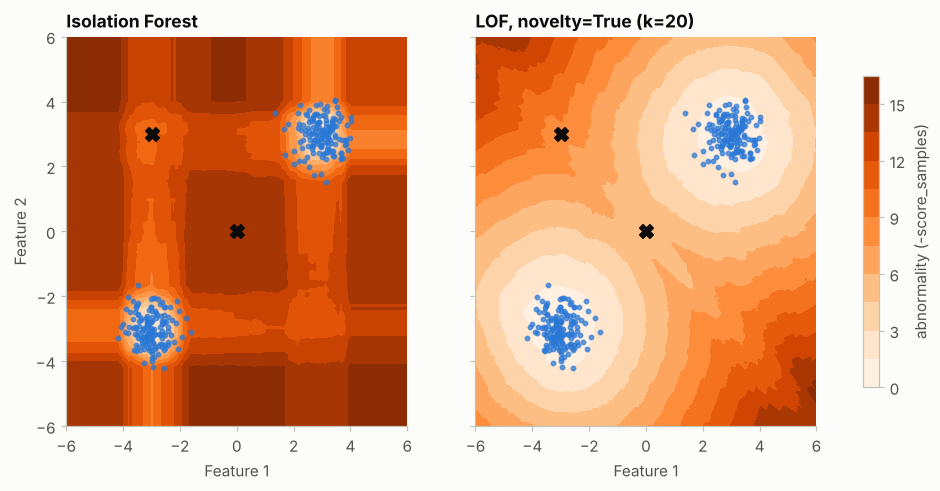

Rank of each probe among the 302 points (1 = most abnormal), fitting on the 300 cluster points only:
  Isolation Forest    : gap (0, 0) ->   1, corner (-3, 3) ->  11
  LOF, novelty=True   : gap (0, 0) ->   2, corner (-3, 3) ->   1


In [16]:
# EXTRA (f): axis-parallel cuts and empty regions
rng = np.random.default_rng(5)
two_clusters = np.vstack([rng.normal([-3, -3], 0.5, (150, 2)), rng.normal([3, 3], 0.5, (150, 2))])
probes = np.array([[0.0, 0.0], [-3.0, 3.0]])
with_probes = np.vstack([two_clusters, probes])

forest_f = IsolationForest(random_state=0).fit(two_clusters)
lof_f = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(two_clusters)

grid = np.linspace(-6, 6, 160)
gx, gy = np.meshgrid(grid, grid)
cells_ = np.c_[gx.ravel(), gy.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, detector in [(axes[0], "Isolation Forest", forest_f), (axes[1], "LOF, novelty=True (k=20)", lof_f)]:
    abnormality = -detector.score_samples(cells_).reshape(gx.shape)
    cs = ax.contourf(gx, gy, abnormality, levels=12, cmap="Oranges")
    ax.scatter(two_clusters[:, 0], two_clusters[:, 1], s=8, color=PALETTE[0], alpha=0.7)
    ax.scatter(probes[:, 0], probes[:, 1], s=80, color=INK, marker="X")
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
fig.colorbar(cs, ax=axes, shrink=0.8, label="abnormality (-score_samples)")
axes[0].set_ylabel("Feature 2")
plt.show()

print("Rank of each probe among the 302 points (1 = most abnormal), fitting on the 300 cluster points only:")
for name, detector in [("Isolation Forest", forest_f), ("LOF, novelty=True", lof_f)]:
    s = -detector.score_samples(with_probes)
    print(f"  {name:20s}: gap (0, 0) -> {rank_of(s, 300):3d}, corner (-3, 3) -> {rank_of(s, 301):3d}")

**(g) Feature importance.** The book's "There's more" in recipe 7 says that Isolation Forest provides feature importances through `feature_importances_()`. A one-line check:

In [17]:
# EXTRA (g): does IsolationForest have feature_importances_?
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(n_estimators=10, random_state=0).fit(X_combined, y_true)
print("fitted IsolationForest has the attribute feature_importances_    :", hasattr(model, "feature_importances_"))
print("fitted RandomForestClassifier has it, for comparison              :", hasattr(random_forest, "feature_importances_"))

fitted IsolationForest has the attribute feature_importances_    : False
fitted RandomForestClassifier has it, for comparison              : True


**Analysis of the extras.**

* **(a)** The forest has $\psi = 256$ points per tree, a depth limit of 8 and $c(\psi) = 10.245$. The score rebuilt from the leaf depths and $c(\text{leaf size})$ differs from `score_samples` by **$1.7 \times 10^{-16}$**: that is the whole algorithm. `offset_` ($-0.5912$) is the 5th percentile of the training scores, `predict` equals "`score_samples < offset_`" for all 320 points, and `decision_function` equals `score_samples - offset_`. The average path length is 13.66 for the normal points and **6.51** for the planted outliers.
* **(b)** Isolating the point closest to the centre takes **16.7 cuts** on average (5th to 95th percentile: 11 to 23); isolating the farthest planted outlier takes **4.3** (2 to 7). In the forest the two distributions of path lengths hardly overlap: the outlier's paths stay below 10, near or below $c(\psi)$, and most of the inlier's paths are between 12 and 18 (the depth limit plus the correction for the points left in the leaf).
* **(c)** The ranking is reproducible only with enough trees: the average rank correlation between two forests is 0.58 with 5 trees, 0.85 with 25, **0.97 with 100** and 0.99 with 400. The AUC barely moves (0.976, 0.986, 0.987, 0.988), but its spread between seeds falls from 0.015 to 0.0007. So the default of 100 trees is adequate for a ranking, and more trees buy stability. The subsample size matters little above 64 (AUC 0.986 for 64, 0.987 for 256 and 0.987 for 320), in line with the theory that small subsamples are enough.
* **(d)** The scores are **identical** for all five settings. Only `offset_` changes ($-0.7455$ for 0.01, $-0.5912$ for 0.05, $-0.4908$ for 0.10, $-0.4179$ for 0.25, $-0.5$ for `'auto'`) and with it the number of flagged points (4, 16, 32, 80 and 26). `'auto'` flags 8% of the points here.
* **(e)** Standardizing the data, or multiplying a feature by 100 and shifting it, gives **exactly the same predictions and scores** (difference 0.0). Isolation Forest is invariant to affine rescaling of the features; the book's advice that normalizing "may still improve results" does not hold for this method.
* **(f)** The Isolation Forest map is made of horizontal and vertical bands: the abnormality of a point depends mostly on how common each *coordinate* is, which is the footprint of axis-parallel cuts. LOF's map is made of rings around the two clusters. The probe in the gap at $(0, 0)$ is rank 1 for Isolation Forest and rank 2 for LOF, so both see it. The corner probe at $(-3, 3)$, which sits where the band of the lower-left cluster meets the band of the upper-right one, is **rank 1 for LOF and only rank 11 for Isolation Forest**. It would still be flagged with `contamination=0.05` (11 is below 15), but it is scored as less abnormal than ten other points (the gap probe and nine of the cluster points). The weakness is real and is one of relative sensitivity, not of blindness.
* **(g)** A fitted `IsolationForest` has **no** `feature_importances_`, while a fitted random forest has one. The sentence in the book's recipe 7 ("Isolation Forest provides feature importance via `feature_importances_()`") does not match the library.

---
## 3. One-Class SVM for novelty detection

*Book: pp. 289–293.*

### Summary

* **Getting ready** — training data with normal points only, `X_train` from `make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)`. The test set stacks 100 "normal" points from `make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)` with 20 uniform "novelty" points (Figure 11.5).
* **How to do it** — `OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)`, `fit(X_train)`, `predict(X_test)`. Figure 11.6 plots the *predicted inliers in red* and the *predicted novelties in blue*. The book comments that the predictions "are probably not the best just based on a visual inspection" and that tuning the hyperparameters could help.
* **How it works** — the model separates the normal data from the origin in a transformed feature space; `kernel` (RBF is the most common), `gamma` (low values give smoother boundaries, high values tighter ones) and `nu` (lower values give tighter margins; higher values are more flexible but may accept novelties). It learns from normal data only and is evaluated on new points.
* **There's more** — scale the features, `decision_function()` for raw scores, high computational cost on large or high-dimensional data.
* **Hands-on exercises** — a 9-step workflow ending with `decision_function()` thresholds.

### Theory

**From a hyperplane to a boundary.** A One-Class SVM (Schölkopf et al., 2001) estimates the *support* of the normal distribution, the region that holds most of its probability. A kernel $k(x, z) = \langle \phi(x), \phi(z) \rangle$ maps the data to a feature space, and the algorithm looks for the hyperplane that separates the mapped points from the origin with the largest margin:

$$\min_{w,\ \xi,\ \rho}\ \ \tfrac12 \lVert w \rVert^2 + \frac{1}{\nu n} \sum_{i=1}^{n} \xi_i - \rho \qquad \text{subject to} \qquad \langle w, \phi(x_i) \rangle \ge \rho - \xi_i,\ \ \xi_i \ge 0.$$

The slack $\xi_i$ lets some training points fall on the wrong side. In the dual, the decision function depends only on kernel values with the **support vectors** (the points with $\alpha_i > 0$):

$$f(x) = \operatorname{sign}\Big(\sum_i \alpha_i\, k(x_i, x) - \rho\Big), \qquad +1 \text{ inside the estimated support},\ -1 \text{ outside}.$$

**The RBF kernel and `gamma`.** With $k(x, z) = \exp(-\gamma \lVert x - z \rVert^2)$ every point has $k(x, x) = 1$, so the mapped points lie on a sphere and "separate from the origin" is the same as "enclose in the smallest ball" (Support Vector Data Description, Tax and Duin, 2004). The parameter $\gamma$ is an inverse squared length scale: a small value gives a smooth, wide boundary, a large value lets each support vector shape its own small bump, and the boundary hugs the training points (overfitting). `gamma='scale'` uses $1 / (n_{\text{features}} \cdot \operatorname{Var}(X))$, where $\operatorname{Var}(X)$ is the variance of *all* entries of the matrix.

**The meaning of `nu`.** $\nu \in (0, 1]$ has a precise meaning (Schölkopf et al., 2001): it is an **upper bound on the fraction of training points outside the boundary** (the training errors) and a **lower bound on the fraction of support vectors**. The book states this in one line; the extras check it. In the dual, the coefficients obey $0 \le \alpha_i \le 1$ and $\sum_i \alpha_i = \nu n$ in the scaling of libsvm used by scikit-learn.

**Cost and scaling.** The method works on the kernel matrix, so training takes between $O(n^2)$ and $O(n^3)$ time: it is comfortable for thousands of points and slow for hundreds of thousands (`SGDOneClassSVM` is the linear, scalable variant). The RBF kernel uses Euclidean distances and `gamma='scale'` a single global variance, so the features must be on comparable scales.

**Outlier or novelty detection?** Trained on clean data it is a novelty detector. Trained on contaminated data it still works as an outlier detector, because `nu` allows a share of the training points to be outside; recipe 7 measures how much contamination costs.

### Book code

The book's test set has two parts. Watch the centre of the "normal" test points: it is generated with `center_box=(0, 1)`, a different call from the one that made the training data. The extras come back to it.

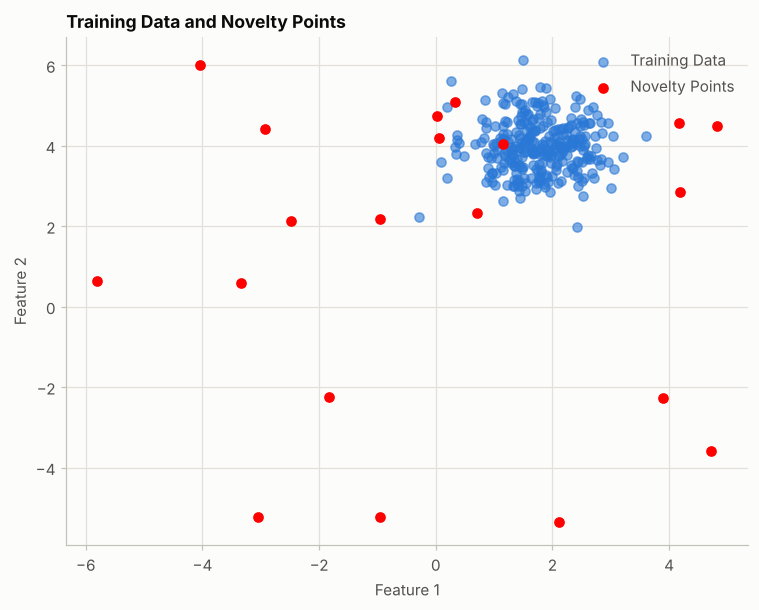

In [18]:
# BOOK CODE (pp. 289-290): load the libraries, generate training data (normal only) and test data (normal + novelty)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Generate training data (normal only)
X_train, _ = make_blobs(n_samples=300, centers=1, cluster_std=0.6, random_state=2024)

# Generate test data (normal + novelty)
X_test_normal, _ = make_blobs(n_samples=100, centers=1, cluster_std=0.6, center_box=(0, 1), random_state=42)
X_test_novelty = np.random.uniform(low=-6, high=6, size=(20, 2))
X_test = np.vstack([X_test_normal, X_test_novelty])

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], label='Training Data', alpha=0.6)
plt.scatter(X_test_novelty[:, 0], X_test_novelty[:, 1], color='red', label='Novelty Points')
plt.title("Training Data and Novelty Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

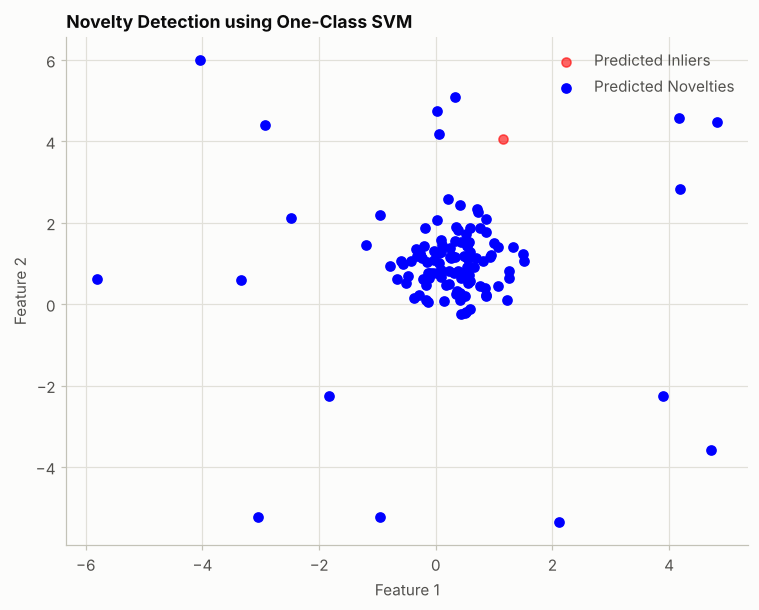

In [19]:
# BOOK CODE (pp. 291-292): One-Class SVM
# Instantiate and fit the model
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
model.fit(X_train)

# Make predictions on the test data
y_pred = model.predict(X_test)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1], color='red', label='Predicted Inliers', alpha=0.6)
plt.scatter(X_test[y_pred == -1, 0], X_test[y_pred == -1, 1], color='blue', label='Predicted Novelties')
plt.title("Novelty Detection using One-Class SVM")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Output analysis.**

* Figure 11.5 shows the training cloud centred at $(1.8, 4.0)$ with the 20 novelty points; the 100 "normal" test points are **not** drawn.
* Figure 11.6 uses **red for the predicted inliers and blue for the predicted novelties**, the opposite of the other figures of the chapter. Of the 120 test points, **119 are blue**: all 100 "normal" test points and 19 of the 20 novelties. A single red point, inside the training cloud, is accepted: it is a novelty that happens to fall where the training data lies.
* The book concludes that the predictions "are probably not the best" and that tuning could help. The model is not at fault: the 100 "normal" test points are generated around a different centre, so rejecting them is the *right* answer. Extra (a) proves it.

### Extra experiments

**(a) Why does the book's result look poor?** The cell prints the centre of the training data and of the book's "normal" test points, counts how many of the 100 normal test points the model accepts, and repeats the evaluation on a corrected test set whose 100 normal points come from the same distribution as the training data (Gaussian, same centre, standard deviation 0.6). The 20 novelty points are the book's. The figure draws the boundary of the model, the line where `decision_function` is 0.

centre of the training data           : [1.76 3.98]
centre of the book's 'normal' test set: [0.3  0.98]  -> 5.6 standard deviations away

                    normal points flagged (false alarms)  novelties found    AUC
test set                                                                        
book's test set                                      100               19  0.596
corrected test set                                     6               19  0.977


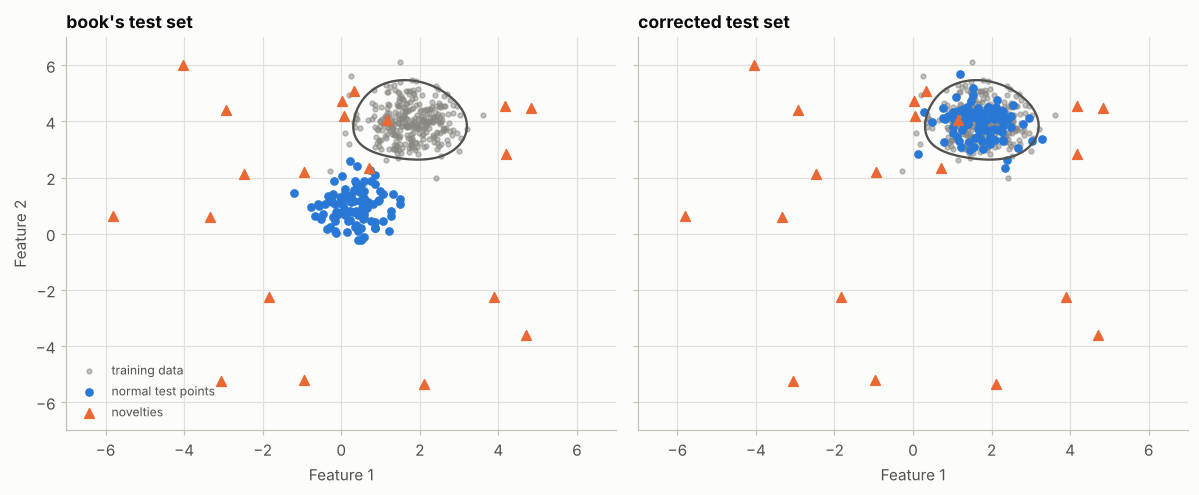

In [20]:
# EXTRA (a): the book's "normal" test points come from another centre than the training data
rng = np.random.default_rng(1)
train_centre = X_train.mean(axis=0)
test_centre_book = X_test_normal.mean(axis=0)
print(f"centre of the training data           : {train_centre.round(2)}")
print(f"centre of the book's 'normal' test set: {test_centre_book.round(2)}  -> {np.linalg.norm(test_centre_book - train_centre) / 0.6:.1f} standard deviations away")

X_test_normal_fixed = rng.normal(train_centre, 0.6, size=(100, 2))            # same distribution as the training data
y_test_truth = np.r_[np.zeros(100), np.ones(20)]                              # 0 = normal, 1 = novelty
sets = {"book's test set": np.vstack([X_test_normal, X_test_novelty]), "corrected test set": np.vstack([X_test_normal_fixed, X_test_novelty])}

rows = []
for name, X_eval in sets.items():
    pred = model.predict(X_eval) == -1
    rows.append({
        "test set": name, "normal points flagged (false alarms)": int(pred[:100].sum()), "novelties found": int(pred[100:].sum()),
        "AUC": roc_auc_score(y_test_truth, -model.decision_function(X_eval)),
    })
print("\n" + pd.DataFrame(rows).set_index("test set").round(3).to_string())

grid = np.linspace(-7, 7, 200)
gx, gy = np.meshgrid(grid, grid)
boundary = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (name, X_eval) in zip(axes, sets.items()):
    ax.contour(gx, gy, boundary, levels=[0], colors=[INK_SOFT], linewidths=1.5)
    ax.scatter(X_train[:, 0], X_train[:, 1], s=10, color=MUTED, alpha=0.5, label="training data")
    ax.scatter(X_eval[:100, 0], X_eval[:100, 1], s=22, color=PALETTE[0], marker="o", label="normal test points")
    ax.scatter(X_eval[100:, 0], X_eval[100:, 1], s=40, color=PALETTE[1], marker="^", label="novelties")
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**(b) What `nu` really does.** For six values of `nu` the model is fitted on the training data. The table reports the share of training points flagged, the share of support vectors, the sum and the maximum of the dual coefficients (`dual_coef_`), and the share of 5,000 *fresh* normal points flagged.

In [21]:
# EXTRA (b): nu is (up to the solver's tolerance) an upper bound on the flagged fraction and a lower bound on the fraction of support vectors
fresh_normal = np.random.default_rng(2).normal(train_centre, 0.6, size=(5000, 2))
rows = []
for nu in [0.01, 0.05, 0.1, 0.2, 0.5, 0.9]:
    m = QuietOneClassSVM(kernel="rbf", gamma="scale", nu=nu).fit(X_train)
    rows.append({
        "nu": nu, "training points flagged": (m.predict(X_train) == -1).mean(), "support vectors / n": len(m.support_) / len(X_train),
        "sum of dual_coef_": m.dual_coef_.sum(), "max of dual_coef_": m.dual_coef_.max(), "fresh normal points flagged": (m.predict(fresh_normal) == -1).mean(),
    })
print(pd.DataFrame(rows).set_index("nu").round(3).to_string())
print(f"\nfor reference, nu x n = {[round(nu * len(X_train), 1) for nu in [0.01, 0.05, 0.1, 0.2, 0.5, 0.9]]}")

      training points flagged  support vectors / n  sum of dual_coef_  max of dual_coef_  fresh normal points flagged
nu                                                                                                                   
0.01                    0.017                0.027                3.0              0.617                        0.018
0.05                    0.047                0.057               15.0              1.000                        0.062
0.10                    0.107                0.110               30.0              1.000                        0.100
0.20                    0.200                0.207               60.0              1.000                        0.194
0.50                    0.500                0.503              150.0              1.000                        0.449
0.90                    0.903                0.903              270.0              1.000                        0.909

for reference, nu x n = [3.0, 15.0, 30.0, 60.0, 150.0, 

**(c) What `gamma` really does.** `gamma='scale'` equals $1 / (2 \operatorname{Var}(X))$ here. Five values are compared, from about 30 times smaller to about 1,000 times larger. For each, the table gives the share of training points flagged, the share of 5,000 fresh *normal* points flagged (false alarms on new data) and the share of "far" novelties found (uniform points in $[-6, 6]^2$ farther than 3.72 standard deviations from the centre). The figure draws the boundary of four of them.

variance of each feature: [0.378 0.406]; variance of all the entries pooled (what 'scale' divides by): 1.627
gamma='scale' is 0.307; nu = 0.05 throughout

         training flagged  clearly outside (f < -0.001)  on the boundary (|f| < 0.001)  fresh normal flagged  far novelties found  support vectors
gamma                                                                                                                                             
0.010               0.057                         0.047                          0.010                 0.056                  1.0               16
0.307               0.047                         0.040                          0.017                 0.062                  1.0               17
3.000               0.130                         0.000                          0.407                 0.140                  1.0               63
30.000              0.350                         0.000                          0.800                 0.658  

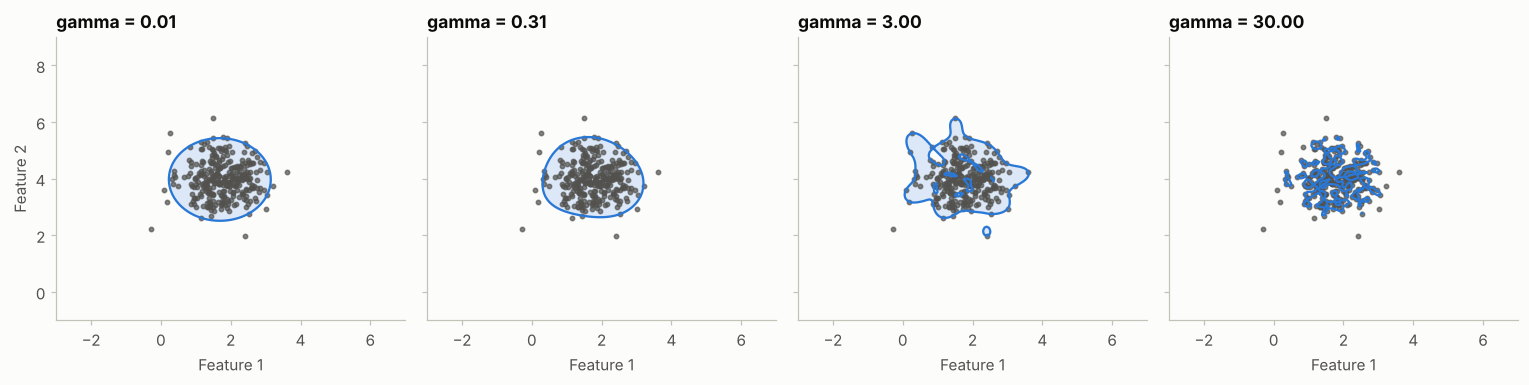

In [22]:
# EXTRA (c): the boundary against gamma - small values underfit, large values memorize the training points
gamma_scale = 1.0 / (X_train.shape[1] * X_train.var())
rng = np.random.default_rng(4)
uniform_points = rng.uniform(-6, 6, size=(6000, 2))
far_novelties = uniform_points[np.linalg.norm(uniform_points - train_centre, axis=1) > 3.72 * 0.6]

rows = []
for gamma in [0.01, gamma_scale, 3, 30, 300]:
    m = QuietOneClassSVM(kernel="rbf", gamma=gamma, nu=0.05).fit(X_train)
    d_train = m.decision_function(X_train)
    rows.append({
        "gamma": round(gamma, 3), "training flagged": (d_train < 0).mean(), "clearly outside (f < -0.001)": (d_train < -1e-3).mean(),
        "on the boundary (|f| < 0.001)": (np.abs(d_train) < 1e-3).mean(), "fresh normal flagged": (m.predict(fresh_normal) == -1).mean(),
        "far novelties found": (m.predict(far_novelties) == -1).mean(), "support vectors": len(m.support_),
    })
print(f"variance of each feature: {X_train.var(axis=0).round(3)}; variance of all the entries pooled (what 'scale' divides by): {X_train.var():.3f}")
print(f"gamma='scale' is {gamma_scale:.3f}; nu = 0.05 throughout\n")
print(pd.DataFrame(rows).set_index("gamma").round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
gx, gy = np.meshgrid(np.linspace(-3, 7, 160), np.linspace(-1, 9, 160))
for ax, gamma in zip(axes, [0.01, gamma_scale, 3, 30]):
    m = QuietOneClassSVM(kernel="rbf", gamma=gamma, nu=0.05).fit(X_train)
    ax.contourf(gx, gy, m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=[-1e9, 0, 1e9], colors=[SURFACE, "#dce8f7"])
    ax.contour(gx, gy, m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), levels=[0], colors=[PALETTE[0]], linewidths=1.5)
    ax.scatter(X_train[:, 0], X_train[:, 1], s=8, color=INK_SOFT, alpha=0.7)
    ax.set_title(f"gamma = {gamma:.2f}")
    ax.set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

**(d) Feature scaling.** Feature 2 is multiplied by 20 (a change of units). The model is fitted on the stretched data directly, and on the same data after `StandardScaler`. Fresh normal points are shifted by 4 standard deviations *along one feature* to make novelties; the table gives the share found for each direction.

In [23]:
# EXTRA (d): gamma='scale' uses one variance for all features, so the units of the features matter
stretch = np.array([1.0, 20.0])
X_train_s = X_train * stretch
rng = np.random.default_rng(6)
probe_normal = rng.normal(train_centre, 0.6, size=(2000, 2)) * stretch
shift_f1 = probe_normal + np.array([4 * 0.6, 0.0])                       # 4 sd along feature 1 (small numbers)
shift_f2 = probe_normal + np.array([0.0, 4 * 0.6 * 20])                  # 4 sd along feature 2 (large numbers)

scaler = StandardScaler().fit(X_train_s)
rows = []
for name, tr, f in [("unscaled", X_train_s, lambda a: a), ("standardized", scaler.transform(X_train_s), scaler.transform)]:
    m = QuietOneClassSVM(gamma="scale", nu=0.05).fit(tr)
    rows.append({
        "model": name, "gamma='scale'": 1.0 / (2 * tr.var()), "normal points flagged": (m.predict(f(probe_normal)) == -1).mean(),
        "shift of 4 sd along feature 1 found": (m.predict(f(shift_f1)) == -1).mean(), "shift of 4 sd along feature 2 found": (m.predict(f(shift_f2)) == -1).mean(),
    })
print(pd.DataFrame(rows).set_index("model").round(4).to_string())

              gamma='scale'  normal points flagged  shift of 4 sd along feature 1 found  shift of 4 sd along feature 2 found
model                                                                                                                       
unscaled             0.0003                  0.050                               0.0535                               0.9705
standardized         0.5000                  0.081                               0.9605                               0.9560


**Analysis of the extras.**

* **(a)** The training data is centred at $(1.76, 3.98)$ and the book's "normal" test points at $(0.30, 0.98)$, **5.6 standard deviations away**, because `make_blobs(..., center_box=(0, 1))` draws its centre elsewhere than the call that built the training data. On the book's test set the model flags all **100 of 100** normal points. On a corrected test set (the same Gaussian as the training data) it flags **6 of 100** (about the 5% that `nu=0.05` allows) and still finds 19 of the 20 novelties; the ROC-AUC goes from 0.596 to **0.977**. The twentieth novelty lies inside the normal cloud.
* **(b)** `nu` behaves as the theory says, up to the tolerance of the solver. The share of flagged training points is 0.017, 0.047, 0.107, 0.200, 0.500 and 0.903 for `nu` from 0.01 to 0.9: close to `nu`, and never more than two points of 300 above it (the solver has a tolerance). The share of support vectors (0.027, 0.057, 0.110, 0.207, 0.503, 0.903) is always at least `nu`. The sum of `dual_coef_` is exactly $\nu n$ (3, 15, 30, 60, 150, 270) and no coefficient exceeds 1. At this `gamma` the share of fresh normal points flagged also follows `nu` (0.018, 0.062, 0.100, 0.194, 0.449 and 0.909), so a larger `nu` is a price paid in false alarms.
* **(c)** `gamma='scale'` is 0.307 here because it divides by the variance of **all entries** (1.627): the two features have means of 1.76 and 3.98, and that difference inflates the pooled variance (the variance of each feature is about 0.39). Between `gamma` = 0.01 and 0.307 the boundary is the same smooth ellipse (fresh normal points flagged: 5.6% and 6.2%, 16 and 17 support vectors). At `gamma` = 3 the boundary is lumpy and 14% of fresh normal points are flagged; at 30 it shrinks into small bumps around single points (66%); at 300 it flags 95%. In these last cases the decision function of the training points collapses to **zero**: 41% (`gamma` = 3), 80% (30) and 98% (300) of them are within 0.001 of the boundary, none is clearly outside, and the "training flagged" column (13%, 35%, 50%) only reflects the sign of rounding errors. The bound on `nu` concerns the points that are clearly outside the boundary, and there are none: the model has memorized the training set. The far novelties are found in all cases (1.0): **a model that rejects everything is not a good detector**, and only the false alarms on fresh normal data reveal it.
* **(d)** With feature 2 multiplied by 20, `gamma='scale'` falls from 0.307 to 0.0003 and the kernel becomes far wider than the spread of feature 1, so it can no longer see a shift along that feature. A shift of 4 standard deviations along feature 1 is found in only **5%** of the cases, against **96%** after `StandardScaler`; a shift along feature 2 is found in both models (97% and 96%). The model trusts the feature with large numbers. The share of normal points flagged stays around the expected level (5.0% and 8.1%).

---
## 4. Detecting outliers with LOF

*Book: pp. 294–297.*

### Summary

* **Getting ready** — clusters of *different densities*: `make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)` (200 points per cluster, a dense one and a loose one) plus 20 points drawn uniformly in $[-6, 10]^2$ after `np.random.seed(2024)`. Figure 11.7.
* **How to do it** — `LocalOutlierFactor(n_neighbors=20, contamination=0.05)` and `fit_predict`. Figure 11.8 colours inliers blue and outliers red.
* **How it works** — three steps: *local density estimation* from the distance to the $k$ nearest neighbours (Chapter 4), the *reachability distance* (the larger of the actual distance and the neighbour's $k$-distance) and the *LOF score* (the average density of the neighbours divided by the density of the point; values much greater than 1 suggest an outlier). The book adds that LOF "does not expose a `.predict()` method for unseen data" and "is strictly an unsupervised anomaly detector used at training time".
* **There's more** — `n_neighbors` controls the sensitivity (small values overfit noise, large values overlook local anomalies); LOF is more robust than global techniques when the density varies; it is "not suitable for novelty detection because it doesn't support prediction on new unseen samples".
* **Hands-on exercises** — an 8-step workflow: generate clusters of different densities with uniform noise, fit with `n_neighbors`, plot, vary `contamination` and `n_neighbors`, observe how the LOF score changes.

### Theory

**Local density, not global distance.** A point in a sparse cluster is far from its neighbours in absolute terms, yet normal; a point near a dense cluster can be close to its neighbours in absolute terms, yet abnormal. LOF (Breunig, Kriegel, Ng and Sander, 2000) therefore compares the density around a point with the density around *its neighbours*, and gives a ratio. For a point $p$ and an integer $k$ (`n_neighbors`):

* the **$k$-distance** of $p$, written $d_k(p)$, is the distance from $p$ to its $k$-th nearest neighbour, and $N_k(p)$ is the set of its $k$ nearest neighbours;
* the **reachability distance** of $p$ from a neighbour $o$ is
$$\text{reach-dist}_k(p, o) = \max\{\, d_k(o),\ d(p, o) \,\},$$
so that points inside the neighbourhood of $o$ are all treated as being at the same distance $d_k(o)$. This smooths the statistical fluctuations of the raw distances;
* the **local reachability density** is the inverse of the mean reachability distance of $p$ from its neighbours:
$$\operatorname{lrd}_k(p) = \left( \frac{1}{|N_k(p)|} \sum_{o \in N_k(p)} \text{reach-dist}_k(p, o) \right)^{-1};$$
* the **Local Outlier Factor** is the average ratio between the density of the neighbours and the density of the point:
$$\operatorname{LOF}_k(p) = \frac{1}{|N_k(p)|} \sum_{o \in N_k(p)} \frac{\operatorname{lrd}_k(o)}{\operatorname{lrd}_k(p)}.$$

**Reading the score.** Inside a cluster the point and its neighbours have the same density, so $\operatorname{LOF} \approx 1$, *whatever the density of the cluster*. A point in a sparser region than its neighbours has $\operatorname{LOF} > 1$; a value of 1.5 means that the neighbours are 50% denser. There is no universal threshold: `contamination` turns the ranking into labels, exactly as for Isolation Forest.

**In scikit-learn.** `negative_outlier_factor_` stores $-\operatorname{LOF}$ for the training data (so that lower means more abnormal, like `score_samples`), and `offset_` is the threshold: the percentile fixed by `contamination` (−1.5 with `'auto'`). The neighbour search uses a KD-tree or a Ball-tree, $O(n \log n)$ in low dimension, and falls back to brute force, $O(n^2)$, when the dimension is high.

**The choice of $k$.** Breunig et al. recommend at least 10 neighbours, to remove statistical fluctuations, and a value larger than the number of points in any group that should be flagged *as a whole*: if $k$ is smaller than a small cluster of outliers, the members of the cluster are each other's neighbours and look normal.

**Outlier or novelty mode.** By default (`novelty=False`) LOF only scores the training data, through `fit_predict` and `negative_outlier_factor_`. With `novelty=True` it can score **new** points through `predict`, `decision_function` and `score_samples`; then `fit_predict` is no longer available. The book's statement that LOF "cannot make predictions on unseen data" is therefore true of the default only; the extras show both modes.

### Book code

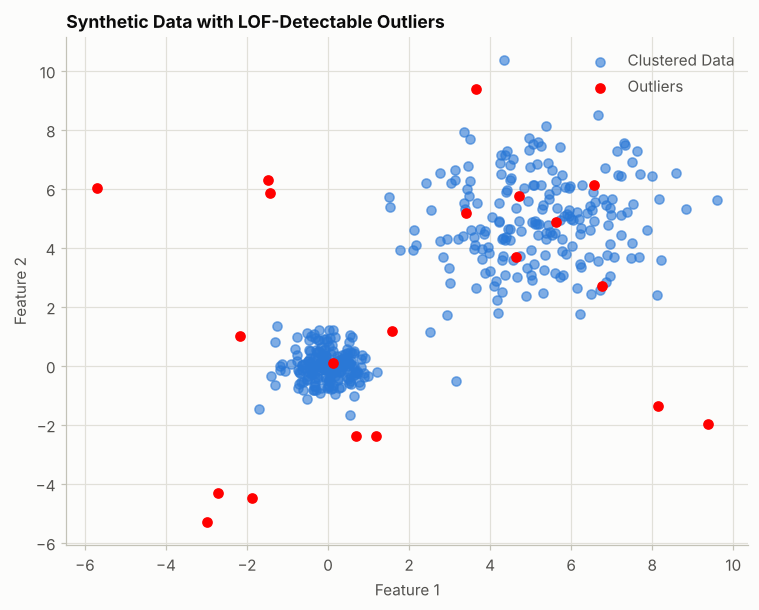

In [24]:
# BOOK CODE (pp. 294-295): load the libraries, create synthetic data with clusters and noise, visualize it
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor

# Create synthetic data with clusters and noise
X, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
np.random.seed(2024)
outliers = np.random.uniform(low=-6, high=10, size=(20, 2))
X_with_outliers = np.vstack([X, outliers])

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], label="Clustered Data", alpha=0.6)
plt.scatter(outliers[:, 0], outliers[:, 1], color='red', label="Outliers")
plt.title("Synthetic Data with LOF-Detectable Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

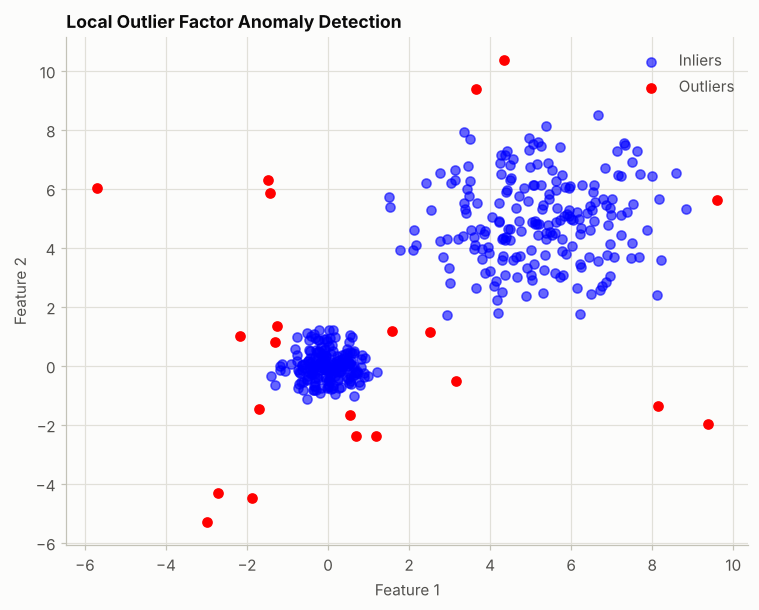

In [25]:
# BOOK CODE (pp. 295-296): Local Outlier Factor
# Initialize and fit the model
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_with_outliers)

# Plot the predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_with_outliers[y_pred == 1, 0], X_with_outliers[y_pred == 1, 1],
            color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_with_outliers[y_pred == -1, 0], X_with_outliers[y_pred == -1, 1],
            color='red', label='Outliers')
plt.title("Local Outlier Factor Anomaly Detection")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

**Output analysis.**

* Figure 11.7 shows a dense cluster at the origin (200 points, standard deviation 0.5), a loose cluster at $(5, 5)$ (200 points, standard deviation 1.5) and 20 points spread over $[-6, 10]^2$; many of them fall in or next to the loose cluster.
* LOF flags **21 points**, 5% of 420: **13 of the 20 planted points, 4 points of the dense cluster and 4 points of the loose cluster**. Seven planted points are kept as normal. The extras show that nine of the planted points lie inside the 99.9% disc of a cluster, so the data itself limits what can be found.

### Extra experiments

**(a) LOF by hand.** The function below follows the definitions step by step with `scipy.spatial.distance.cdist`: the $k$ nearest neighbours of every point, the $k$-distances, the reachability distances, the local reachability densities and the ratio. Its result is compared with `negative_outlier_factor_`. A second table shows the intermediate quantities for three points: the planted point with the highest LOF, and the median point of each cluster.

In [26]:
# EXTRA (a): LOF computed from its definition
from scipy.spatial.distance import cdist


def lof_by_hand(data, k):
    """Local Outlier Factor of Breunig et al. (2000). Returns LOF, lrd, k-distance and the neighbour indices of every point."""
    d = cdist(data, data)
    np.fill_diagonal(d, np.inf)                                         # a point is not its own neighbour
    neighbours = np.argsort(d, axis=1)[:, :k]                           # N_k(p)
    dist_to_neighbours = np.take_along_axis(d, neighbours, axis=1)
    k_distance = dist_to_neighbours[:, -1]                              # d_k(p)
    reach = np.maximum(dist_to_neighbours, k_distance[neighbours])      # reach-dist_k(p, o) = max(d_k(o), d(p, o))
    lrd = 1.0 / reach.mean(axis=1)
    return lrd[neighbours].mean(axis=1) / lrd, lrd, k_distance, neighbours


lof_hand, lrd, k_dist, neigh = lof_by_hand(X_with_outliers, k=20)
print(f"largest difference between the LOF by hand and -negative_outlier_factor_: {np.abs(lof_hand + lof.negative_outlier_factor_).max():.1e}")
print(f"offset_ = {lof.offset_:.4f}; 5th percentile of negative_outlier_factor_ = {np.percentile(lof.negative_outlier_factor_, 5):.4f}  (so a point is flagged when its LOF exceeds {-lof.offset_:.3f})")

cluster_id = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)[1]
medians = {}
for c, name in [(0, "median point of the dense cluster"), (1, "median point of the loose cluster")]:
    members = np.where(cluster_id == c)[0]
    medians[name] = members[np.argsort(lof_hand[members])[len(members) // 2]]
chosen = {"highest-LOF planted point": 400 + int(np.argmax(lof_hand[400:])), **medians}
rows = []
for name, i in chosen.items():
    rows.append({
        "point": name, "d_k(p)": k_dist[i], "mean reach-dist": 1 / lrd[i], "lrd(p)": lrd[i],
        "mean lrd of the neighbours": lrd[neigh[i]].mean(), "LOF": lof_hand[i],
    })
print("\n" + pd.DataFrame(rows).set_index("point").round(3).to_string())

largest difference between the LOF by hand and -negative_outlier_factor_: 1.6e-09
offset_ = -1.8509; 5th percentile of negative_outlier_factor_ = -1.8509  (so a point is flagged when its LOF exceeds 1.851)

                                   d_k(p)  mean reach-dist  lrd(p)  mean lrd of the neighbours     LOF
point                                                                                                 
highest-LOF planted point           7.521            6.967   0.144                       1.441  10.037
median point of the dense cluster   0.326            0.304   3.284                       3.463   1.054
median point of the loose cluster   0.979            0.918   1.089                       1.130   1.037


**(b) What LOF flagged.** The figure draws every point with a size that grows with its LOF. The cell counts the flagged points by origin: planted points, and normal points of the dense and of the loose cluster. It also counts the planted points that fall inside the 99.9% disc of one of the two clusters, which no detector can separate from the normal data (recipe 1(a)), and compares LOF with Isolation Forest by ROC-AUC (recipe 5) and with an *oracle* that ranks the points by the true density of the generator.

points flagged: 21  = 13 planted + 4 from the dense cluster + 4 from the loose cluster
planted points inside the 99.9% disc of a cluster: 9 of 20 (1 in the dense one, 8 in the loose one)
LOF of the normal points: median 1.04, 95th percentile 1.47, maximum 4.89
LOF of the planted points: median 3.03, minimum 0.96

LOF (k=20)                                0.767
Isolation Forest                          0.840
oracle (true density of the generator)    0.845


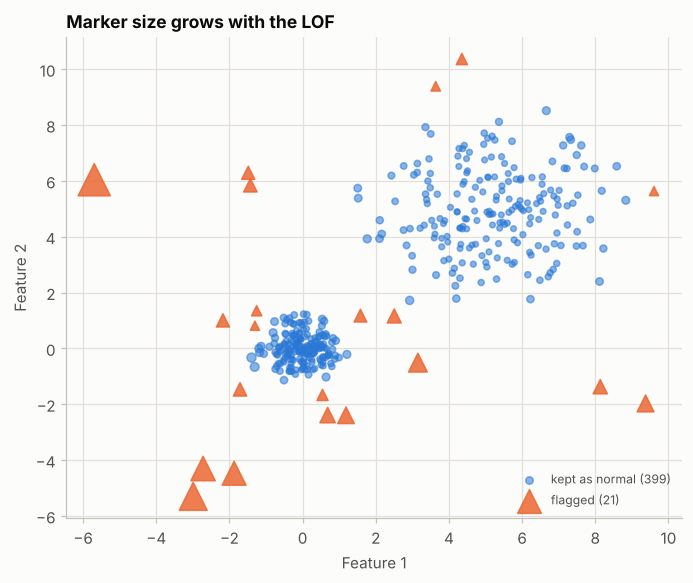

In [27]:
# EXTRA (b): where LOF flags, and what the data allows
from scipy.stats import chi2, multivariate_normal
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score

flag = y_pred == -1
truth = np.r_[np.zeros(400), np.ones(20)]
r999 = np.sqrt(chi2.ppf(0.999, df=2))
inside_dense = np.linalg.norm(outliers - [0, 0], axis=1) < r999 * 0.5
inside_loose = np.linalg.norm(outliers - [5, 5], axis=1) < r999 * 1.5
inside_any = inside_dense | inside_loose

print(f"points flagged: {flag.sum()}  = {flag[400:].sum()} planted + {flag[:400][cluster_id == 0].sum()} from the dense cluster + {flag[:400][cluster_id == 1].sum()} from the loose cluster")
print(f"planted points inside the 99.9% disc of a cluster: {inside_any.sum()} of 20 ({inside_dense.sum()} in the dense one, {inside_loose.sum()} in the loose one)")
print(f"LOF of the normal points: median {np.median(lof_hand[:400]):.2f}, 95th percentile {np.percentile(lof_hand[:400], 95):.2f}, maximum {lof_hand[:400].max():.2f}")
print(f"LOF of the planted points: median {np.median(lof_hand[400:]):.2f}, minimum {lof_hand[400:].min():.2f}")

true_density = 0.5 * multivariate_normal([0, 0], 0.5**2 * np.eye(2)).pdf(X_with_outliers) + 0.5 * multivariate_normal([5, 5], 1.5**2 * np.eye(2)).pdf(X_with_outliers)
auc_table = pd.Series({
    "LOF (k=20)": roc_auc_score(truth, lof_hand),
    "Isolation Forest": roc_auc_score(truth, -IsolationForest(random_state=0).fit(X_with_outliers).score_samples(X_with_outliers)),
    "oracle (true density of the generator)": roc_auc_score(truth, -np.log(true_density)),
}, name="ROC-AUC")
print("\n" + auc_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.scatter(X_with_outliers[~flag, 0], X_with_outliers[~flag, 1], s=14 * lof_hand[~flag] ** 1.5, color=PALETTE[0], alpha=0.55, label=f"kept as normal ({(~flag).sum()})")
ax.scatter(X_with_outliers[flag, 0], X_with_outliers[flag, 1], s=14 * lof_hand[flag] ** 1.5, color=PALETTE[1], marker="^", alpha=0.85, label=f"flagged ({flag.sum()})")
ax.set_title("Marker size grows with the LOF")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**(c) The choice of `n_neighbors`, and local against global outliers.** A second dataset is built to contain *local* outliers: a dense cluster (300 points, standard deviation 0.5), a loose cluster (300 points, standard deviation 1.5, centre 6 units to the right) and 15 points on a circle of radius 1.8 around the dense cluster, that is 3.6 standard deviations from its centre. Seen from the loose cluster they are ordinary (its own points are 1.5 standard deviations apart), but next to the dense cluster they are far. The cell computes the ROC-AUC of LOF for different `n_neighbors` on the book's data and on this one, and compares with Isolation Forest.

             book's data  data with local outliers
n_neighbors                                       
2                  0.619                     0.700
3                  0.786                     0.761
5                  0.847                     0.966
10                 0.827                     0.997
20                 0.767                     0.998
35                 0.768                     0.998
50                 0.766                     0.997
100                0.766                     0.996
200                0.855                     0.989

Isolation Forest (default settings): book's data 0.840, data with local outliers 0.907


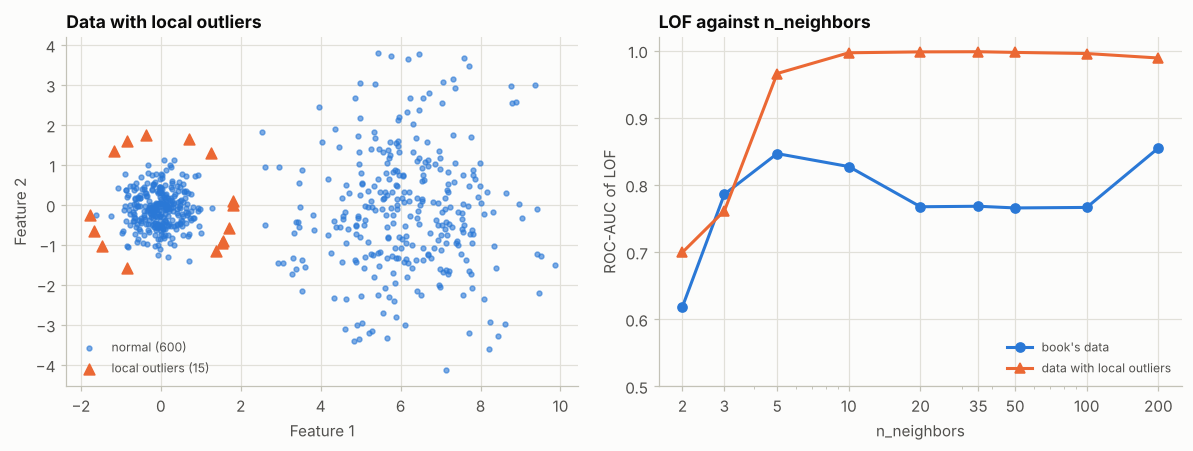

In [28]:
# EXTRA (c): ROC-AUC of LOF against n_neighbors, on the book's data and on data with local outliers
def make_density_data(seed, n_local=15):
    """Dense cluster, loose cluster and n_local points on a circle of radius 1.8 around the dense cluster (local outliers)."""
    rng = np.random.default_rng(seed)
    dense = rng.normal([0, 0], 0.5, size=(300, 2))
    loose = rng.normal([6, 0], 1.5, size=(300, 2))
    angle = rng.uniform(0, 2 * np.pi, n_local)
    local = 1.8 * np.c_[np.cos(angle), np.sin(angle)]
    return np.vstack([dense, loose, local]), np.r_[np.zeros(600), np.ones(n_local)]


X_local, y_local = make_density_data(seed=7)
ks = [2, 3, 5, 10, 20, 35, 50, 100, 200]
rows = []
for k in ks:
    rows.append({
        "n_neighbors": k,
        "book's data": roc_auc_score(truth, -LocalOutlierFactor(n_neighbors=k).fit(X_with_outliers).negative_outlier_factor_),
        "data with local outliers": roc_auc_score(y_local, -LocalOutlierFactor(n_neighbors=k).fit(X_local).negative_outlier_factor_),
    })
sweep = pd.DataFrame(rows).set_index("n_neighbors")
if_book = roc_auc_score(truth, -IsolationForest(random_state=0).fit(X_with_outliers).score_samples(X_with_outliers))
if_local = roc_auc_score(y_local, -IsolationForest(random_state=0).fit(X_local).score_samples(X_local))
print(sweep.round(3).to_string())
print(f"\nIsolation Forest (default settings): book's data {if_book:.3f}, data with local outliers {if_local:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(X_local[y_local == 0, 0], X_local[y_local == 0, 1], s=10, color=PALETTE[0], alpha=0.6, label="normal (600)")
axes[0].scatter(X_local[y_local == 1, 0], X_local[y_local == 1, 1], s=50, color=PALETTE[1], marker="^", label="local outliers (15)")
axes[0].set_title("Data with local outliers")
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].set_aspect("equal")
axes[0].legend(loc="lower left", fontsize=8)
for column, colour, marker in [("book's data", PALETTE[0], "o"), ("data with local outliers", PALETTE[1], "^")]:
    axes[1].plot(sweep.index, sweep[column], color=colour, marker=marker, label=column)
axes[1].set_xscale("log")
axes[1].set_xticks(ks)
axes[1].set_xticklabels([str(k) for k in ks])
axes[1].set_ylim(0.5, 1.02)
axes[1].set_xlabel("n_neighbors")
axes[1].set_ylabel("ROC-AUC of LOF")
axes[1].set_title("LOF against n_neighbors")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**(d) LOF can predict on new data.** The book says it cannot. The cell asks the default LOF for `predict`, asks the `novelty=True` LOF for `fit_predict`, then fits `novelty=True` on the 400 normal points of the book's data (the *training* data must be clean in this mode) and scores five new probes: the centre of each cluster, a point between them, a point outside, and a point far away. It also compares `score_samples` on the training data with `negative_outlier_factor_`, because the documentation advises against using the former on training data.

In [29]:
# EXTRA (d): novelty=True lets LOF score new points
for label, make in [("novelty=False, predict()", lambda: LocalOutlierFactor(n_neighbors=20).fit(X_with_outliers).predict(X_with_outliers[:2])),
                    ("novelty=True, fit_predict()", lambda: LocalOutlierFactor(n_neighbors=20, novelty=True).fit_predict(X_with_outliers))]:
    try:
        make()
    except AttributeError as error:
        print(f"{label:28s} -> AttributeError: {error}")

novelty_lof = LocalOutlierFactor(n_neighbors=20, novelty=True).fit(X)               # X: the 400 normal points
probes = np.array([[0.0, 0.0], [5.0, 5.0], [2.5, 2.5], [0.0, 3.0], [9.0, 9.0]])
names = ["centre of the dense cluster", "centre of the loose cluster", "between the clusters", "off to the side of the dense one", "far away"]
table = pd.DataFrame({"predict": novelty_lof.predict(probes), "LOF = -score_samples": -novelty_lof.score_samples(probes)}, index=names)
print("\nLOF fitted on the 400 normal points (novelty=True), five new probes:")
print(table.round(2).to_string())

print(f"\nmax |score_samples(training data) - negative_outlier_factor_| : {np.abs(novelty_lof.score_samples(X) - novelty_lof.negative_outlier_factor_).max():.2f}")
print(f"share of the training points flagged by predict(training data): {(novelty_lof.predict(X) == -1).mean():.3f}")

novelty=False, predict()     -> AttributeError: This 'LocalOutlierFactor' has no attribute 'predict'
novelty=True, fit_predict()  -> AttributeError: This 'LocalOutlierFactor' has no attribute 'fit_predict'

LOF fitted on the 400 normal points (novelty=True), five new probes:
                                  predict  LOF = -score_samples
centre of the dense cluster             1                  0.97
centre of the loose cluster             1                  0.99
between the clusters                    1                  1.37
off to the side of the dense one       -1                  3.65
far away                               -1                  2.07

max |score_samples(training data) - negative_outlier_factor_| : 0.19
share of the training points flagged by predict(training data): 0.030


**Analysis of the extras.**

* **(a)** The LOF written from the definition differs from `-negative_outlier_factor_` by **$1.6 \times 10^{-9}$** (scikit-learn adds $10^{-10}$ to a denominator). `offset_` is $-1.8509$: a point is flagged when its LOF exceeds 1.851. The three points of the table show the scale-free nature of the score: the dense cluster has a local reachability density of 3.28 and the loose cluster of 1.09, a factor of 3, yet the median points of both have a LOF of about **1.04** (1.054 and 1.037), because their neighbours have the same density as they do. The planted point with the highest LOF has a density of 0.144 against 1.44 for its neighbours: a LOF of **10.04**.
* **(b)** 21 flagged = 13 planted + 4 + 4. Nine of the 20 planted points are inside the 99.9% disc of a cluster (8 in the loose one, whose disc is large), so at most 11 can be separated by distance; LOF flagged 13 because a few of the points inside the loose cluster happen to sit in a sparser spot. Normal points have a median LOF of 1.04, a 95th percentile of 1.47 and a maximum of 4.89; the planted points have a median of 3.03 and a minimum of 0.96. By ROC-AUC LOF scores **0.767**, Isolation Forest **0.840** and the oracle 0.845: **on the book's own data Isolation Forest is better than LOF**, and close to the ceiling, which does not support the book's expectation that LOF is the better choice for varying densities (extra (c) shows when it is).
* **(c)** On the data with local outliers, LOF reaches an AUC of **0.998 for `n_neighbors` from 20 to 35** (0.997 from 10 to 50), against **0.907** for Isolation Forest: the 15 points at 3.6 standard deviations from the dense cluster are much easier to see for a method that compares each point with its own neighbours (Isolation Forest scores 0.907 on this same data; in recipe 7(c), over five similar draws, Isolation Forest and the One-Class SVM reach 0.923 and 0.882). Small values fail (0.700 for `n_neighbors=2`, 0.761 for 3), and 5 already gives 0.966; this agrees with the advice to use at least about 10. On the book's data the AUC is not monotone in `n_neighbors` (0.847 for 5, 0.767 for 20 to 100, 0.855 for 200), because the planted points are uniform noise spread over both clusters, and the best value for one dataset is not the best for another.
* **(d)** The default LOF has no `predict` and the `novelty=True` LOF has no `fit_predict`, as the error messages say. Fitted on the 400 normal points with `novelty=True`, LOF scores new points: the cluster centres get a LOF of 0.97 and 0.99 (inliers), a point between the clusters 1.37 (still an inlier, below the 1.5 of `'auto'`), a point at the side of the dense cluster **3.65** and a far point 2.07 (both novelties). The sentence "LOF is not suitable for novelty detection because it doesn't support prediction on new unseen samples" is therefore true only of the default mode. Applying `score_samples` to the *training* data gives values that differ from `negative_outlier_factor_` by up to 0.19, because each point is then its own nearest neighbour; this is why the documentation advises against it.

---
## 5. Evaluating outlier detection models

*Book: pp. 298–302.*

### Summary

* **Getting ready** — labelled data: 300 inliers from `make_blobs(centers=[[0, 0]], cluster_std=0.6, random_state=2024)` and 30 outliers from `np.random.uniform(-6, 6, (30, 2))` (this time *without* a seed: the draw continues the global stream), with `y_true` equal to 0 for inliers and 1 for outliers.
* **How to do it** — `IsolationForest(contamination=0.09, random_state=2024)`; `predict` returns +1/−1 and `np.where(y_pred == 1, 0, 1)` converts it to 0/1. Then a confusion matrix drawn as a seaborn heatmap (Figure 11.10), `classification_report(..., output_dict=True)` shown as a styled DataFrame (Figure 11.11), and `roc_auc_score(y_true, model.decision_function(X))`.
* **How it works** — precision (share of flagged points that are real outliers), recall (share of real outliers found), F1 (harmonic mean), the confusion matrix and the ROC-AUC ("the model's ability to rank true outliers above inliers"). Without labels: expert validation, reconstruction error, or proxy metrics such as prediction stability.
* **There's more** — the cost of errors depends on the use case (a missed fraud may cost more than a false alarm); tune the threshold on `decision_function()`; use stratified cross-validation on labelled anomaly data.
* **Hands-on exercises** — an 8-step workflow ending with different contamination levels and threshold tuning.

### Theory

**Why accuracy is the wrong tool.** Outliers are rare, so a detector that never flags anything is "accurate". With the outlier as the positive class, the confusion matrix counts true positives $TP$, false positives $FP$, false negatives $FN$ and true negatives $TN$, and

$$\text{precision} = \frac{TP}{TP + FP}, \qquad \text{recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}, \qquad \text{FPR} = \frac{FP}{FP + TN}.$$

*Recall* is the true positive rate (TPR). Precision and recall pull in opposite directions: flagging more points raises recall and lowers precision. These three numbers depend on the **threshold**, that is on `contamination`.

**A consequence worth knowing.** When the detector flags exactly as many points as there are true outliers, $TP + FP = TP + FN$, so precision, recall and $F_1$ are **equal** by construction. This happens when `contamination` equals the true share, which is what the book does (30 outliers out of 330 is 0.0909, and `contamination=0.09`).

**Threshold-free metrics: ROC and precision-recall curves.** Sweeping the threshold over the scores gives the ROC curve (TPR against FPR). The **ROC-AUC** is the area under it, and it has a probabilistic meaning (Fawcett, 2006): it is the probability that a randomly chosen outlier gets a **higher abnormality score** than a randomly chosen inlier, $\text{AUC} = P\big(s(x^{+}) > s(x^{-})\big)$ (ties count one half). It is 0.5 for a random ranking and 1 for a perfect one. When the positives are rare, the **precision-recall curve** and the **average precision**, $\text{AP} = \sum_n (R_n - R_{n-1}) P_n$, are more informative than the ROC curve (Davis and Goadrich, 2006; Saito and Rehmsmeier, 2015), because a large number of true negatives keeps the FPR small even when many false alarms are raised; a random detector has an AP equal to the prevalence of outliers.

**The orientation of the score.** `roc_auc_score(y_true, y_score)` expects a score that is **higher for the positive class**. Here the positive class is "outlier", but `decision_function` and `score_samples` are **higher for inliers** (negative means outlier). The score passed to the metric must therefore be $-$`decision_function(X)`. If the sign is wrong, the AUC is $1 - \text{AUC}$: an AUC far *below* 0.5 means "inverted", not "bad".

**Evaluation without labels.** Real data usually has no labels. Options: review the top-ranked points with an expert; check the **stability** of the ranking (same detector, different seeds or subsamples); inject synthetic anomalies as a sanity check; use label-free criteria such as the Excess-Mass and Mass-Volume curves (Goix, 2016). Campos et al. (2016) show how much the choice of evaluation matters for unsupervised outlier detection.

**A ceiling set by the data.** In synthetic data the outliers are drawn uniformly over a region that also contains the normal cluster: some of them land inside the cluster and are undetectable by any method. The AUC of an *oracle* that knows the generating distribution tells how much can be achieved at all.

### Book code

The data is drawn with no seed of its own: it continues the stream of recipes 1 to 4, so its numbers are those of the book only when the notebook is run in order.

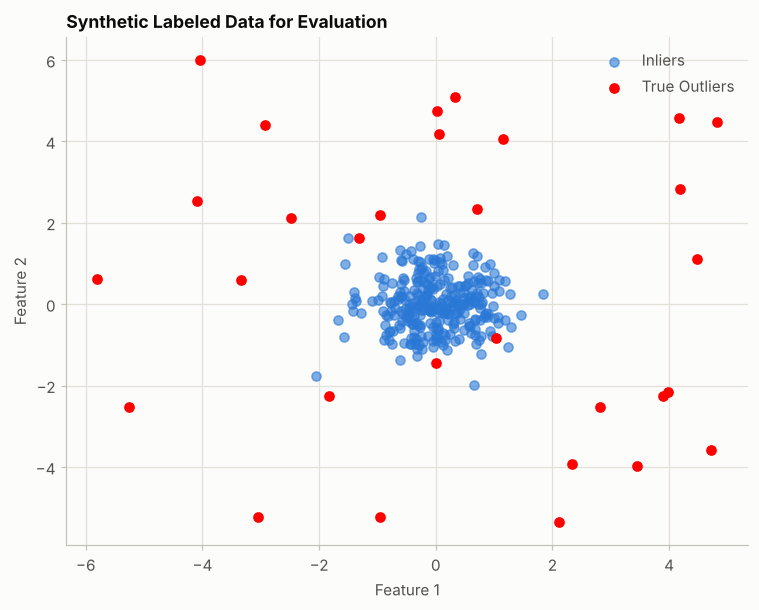

In [30]:
# BOOK CODE (pp. 298-299): load the libraries and generate labeled synthetic data
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns

# Generate labeled synthetic data
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))  # 0 = inlier, 1 = outlier

# Visualize the data
plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0][:, 0], X[y_true == 0][:, 1], label='Inliers', alpha=0.6)
plt.scatter(X[y_true == 1][:, 0], X[y_true == 1][:, 1], color='red', label='True Outliers')
plt.title("Synthetic Labeled Data for Evaluation")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

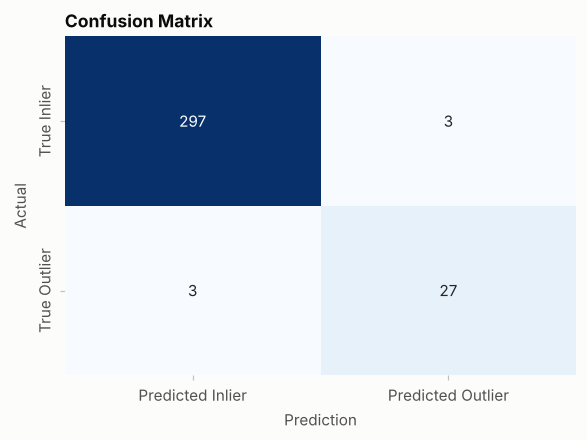

,precision,recall,f1-score,support
0,0.990,0.990,0.990,300
1,0.900,0.900,0.900,30
accuracy,0.982,0.982,0.982,1
macro avg,0.945,0.945,0.945,330
weighted avg,0.982,0.982,0.982,330


ROC-AUC Score: 0.005111111111111106


In [31]:
# BOOK CODE (pp. 300-301): Isolation Forest, confusion matrix, classification report and ROC-AUC
import pandas as pd

# Fit the model and get predictions
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
y_pred = model.predict(X)
y_pred_binary = np.where(y_pred == 1, 0, 1)  # convert to 0 = inlier, 1 = outlier

# Generate and plot confusion matrix
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Print classification report as a styled DataFrame and AUC
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)
print("ROC-AUC Score:", roc_auc_score(y_true, model.decision_function(X)))

**Output analysis.**

* Figure 11.9 (drawn by the first listing) shows the 300 inliers and the 30 uniform outliers. The confusion matrix of Figure 11.10 is $\begin{pmatrix} 297 & 3 \\ 3 & 27 \end{pmatrix}$: 27 of the 30 outliers are found and 3 inliers are flagged. The classification report gives precision, recall and F1 of **0.990** for the inliers (support 300) and **0.900** for the outliers (support 30), an accuracy of **0.982**, a macro average of 0.945 and a weighted average of 0.982. These numbers are those of the saved output of the official notebook.
* The last line prints `ROC-AUC Score: 0.005111111111111106`, again as in the official notebook, with no comment in the text. A ROC-AUC of 0.005 would mean that the detector is almost *perfectly wrong*; it is in fact almost perfectly right, with the score in the wrong orientation. Extra (a) explains it.

### Extra experiments

**(a) The sign of the ROC-AUC.** The same scores are given to `roc_auc_score` with the book's orientation, with the orientation the theory requires, with `score_samples` (which has the same orientation as `decision_function`), and as hard 0/1 labels.

In [32]:
# EXTRA (a): the orientation of the score decides the AUC
from sklearn.metrics import average_precision_score, balanced_accuracy_score

rows = {
    "decision_function (the book)": roc_auc_score(y_true, model.decision_function(X)),
    "-decision_function": roc_auc_score(y_true, -model.decision_function(X)),
    "score_samples": roc_auc_score(y_true, model.score_samples(X)),
    "-score_samples": roc_auc_score(y_true, -model.score_samples(X)),
    "hard 0/1 labels (y_pred_binary)": roc_auc_score(y_true, y_pred_binary),
}
print(pd.Series(rows, name="ROC-AUC").round(4).to_string())
print(f"\n1 - the book's value = {1 - rows['decision_function (the book)']:.4f}")
print(f"balanced accuracy of the hard labels = {balanced_accuracy_score(y_true, y_pred_binary):.4f}  (the AUC of 0/1 labels is exactly this number)")

decision_function (the book)       0.0051
-decision_function                 0.9949
score_samples                      0.0051
-score_samples                     0.9949
hard 0/1 labels (y_pred_binary)    0.9450

1 - the book's value = 0.9949
balanced accuracy of the hard labels = 0.9450  (the AUC of 0/1 labels is exactly this number)


**(b) The accuracy trap.** A detector that flags nothing, and the book's detector, on the same data.

In [33]:
# EXTRA (b): accuracy against recall for a detector that does nothing
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

nothing = np.zeros_like(y_true)                                    # "flag nothing"
rows = []
for name, pred in [("flags nothing", nothing), ("Isolation Forest, contamination=0.09", y_pred_binary)]:
    rows.append({
        "detector": name, "accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "outliers found": int(((pred == 1) & (y_true == 1)).sum()),
    })
print(pd.DataFrame(rows).set_index("detector").round(3).to_string())
print(f"\nshare of inliers in the data: {(y_true == 0).mean():.3f}")

                                      accuracy  precision  recall   F1  outliers found
detector                                                                              
flags nothing                            0.909        0.0     0.0  0.0               0
Isolation Forest, contamination=0.09     0.982        0.9     0.9  0.9              27

share of inliers in the data: 0.909


**(c) The threshold: `contamination` against the true share.** The same forest is fitted with `contamination` from 0.01 to 0.25, the true share being $30/330 = 0.0909$. The forest is identical each time (same `random_state`), so only the threshold moves.

In [34]:
# EXTRA (c): precision, recall and F1 as the threshold moves
rows = []
for c in [0.01, 0.03, 0.05, 0.09, 0.15, 0.25]:
    pred = IsolationForest(contamination=c, random_state=2024).fit(X).predict(X) == -1
    rows.append({
        "contamination": c, "points flagged": int(pred.sum()), "true outliers found": int(pred[300:].sum()),
        "precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
    })
print(f"true share of outliers: {y_true.mean():.4f}\n")
print(pd.DataFrame(rows).set_index("contamination").round(3).to_string())

true share of outliers: 0.0909

               points flagged  true outliers found  precision  recall     F1
contamination                                                               
0.01                        4                    4      1.000   0.133  0.235
0.03                       10                   10      1.000   0.333  0.500
0.05                       17                   17      1.000   0.567  0.723
0.09                       30                   27      0.900   0.900  0.900
0.15                       50                   29      0.580   0.967  0.725
0.25                       83                   30      0.361   1.000  0.531


**(d) ROC and precision-recall curves.** The scores are $-$`decision_function`. The three marks on each curve are the operating points reached by `contamination` = 0.03, 0.09 and 0.25 (the threshold is the percentile of the scores). The dashed line of the right panel is the precision of a random detector, the prevalence of outliers.

ROC-AUC = 0.9949; average precision = 0.9663; prevalence of outliers = 0.0909


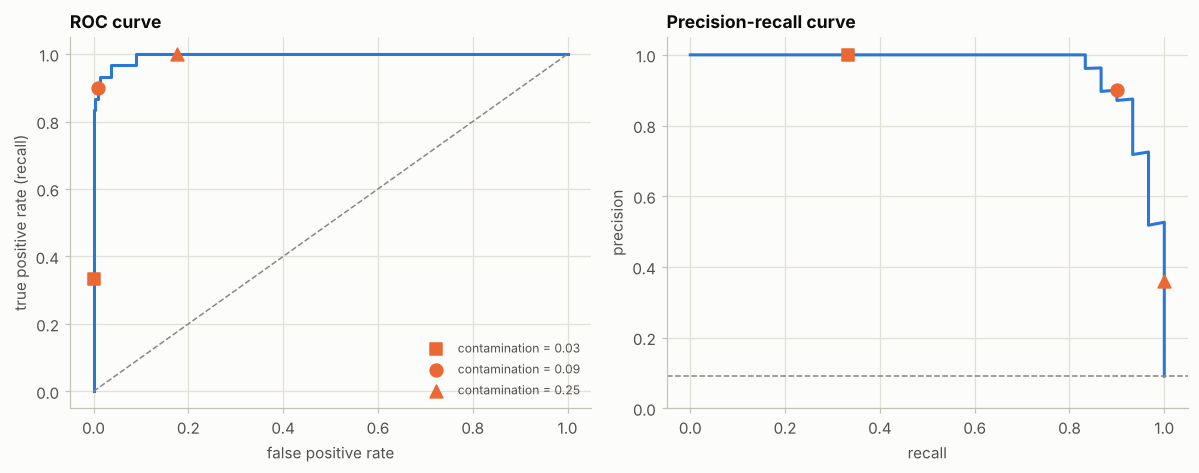

In [35]:
# EXTRA (d): ROC and precision-recall curves with the operating points of three contamination values
from sklearn.metrics import precision_recall_curve, roc_curve

abnormality = -model.decision_function(X)
fpr, tpr, _ = roc_curve(y_true, abnormality)
precision_curve, recall_curve, _ = precision_recall_curve(y_true, abnormality)
print(f"ROC-AUC = {roc_auc_score(y_true, abnormality):.4f}; average precision = {average_precision_score(y_true, abnormality):.4f}; prevalence of outliers = {y_true.mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].plot(fpr, tpr, color=PALETTE[0])
axes[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[1].plot(recall_curve, precision_curve, color=PALETTE[0])
axes[1].axhline(y_true.mean(), color=MUTED, ls="--", lw=1)
for c, marker in [(0.03, "s"), (0.09, "o"), (0.25, "^")]:
    pred = IsolationForest(contamination=c, random_state=2024).fit(X).predict(X) == -1
    axes[0].scatter(pred[y_true == 0].mean(), pred[y_true == 1].mean(), s=70, color=PALETTE[1], marker=marker, zorder=3, label=f"contamination = {c}")
    axes[1].scatter(recall_score(y_true, pred), precision_score(y_true, pred), s=70, color=PALETTE[1], marker=marker, zorder=3, label=f"contamination = {c}")
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title("ROC curve")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

**(e) The ceiling set by the data.** The generator is known: inliers are $N(0, 0.6^2 I)$ and the outliers are uniform over a large square, so the best possible ranking is by the density of the inlier law. That *oracle* gives the highest AUC a detector could reach on this sample. The cell also lists, in standard deviations from the centre, the outliers the forest missed and the inliers it flagged.

In [36]:
# EXTRA (e): the oracle ranking, and the points the forest got wrong
oracle_score = -multivariate_normal([0, 0], 0.6**2 * np.eye(2)).logpdf(X)          # low density of the inlier law = abnormal
print(f"ROC-AUC: Isolation Forest {roc_auc_score(y_true, abnormality):.4f}, oracle {roc_auc_score(y_true, oracle_score):.4f}")
print(f"average precision: Isolation Forest {average_precision_score(y_true, abnormality):.4f}, oracle {average_precision_score(y_true, oracle_score):.4f}")

dist_sd = np.linalg.norm(X, axis=1) / 0.6                                          # distance to the true centre (0, 0), in standard deviations
flagged = y_pred_binary == 1
print(f"\noutliers that fall inside the 99.9% disc ({np.sqrt(chi2.ppf(0.999, 2)):.2f} sd) of the inliers: {(dist_sd[300:] < np.sqrt(chi2.ppf(0.999, 2))).sum()} of 30")
print(f"missed outliers (false negatives), distance in sd : {np.sort(dist_sd[(y_true == 1) & ~flagged]).round(2)}")
print(f"flagged inliers (false positives), distance in sd : {np.sort(dist_sd[(y_true == 0) & flagged]).round(2)}")

ROC-AUC: Isolation Forest 0.9949, oracle 0.9942
average precision: Isolation Forest 0.9663, oracle 0.9647

outliers that fall inside the 99.9% disc (3.72 sd) of the inliers: 3 of 30
missed outliers (false negatives), distance in sd : [2.21 2.41 3.49]
flagged inliers (false positives), distance in sd : [3.1 3.5 4.5]


**(f) How much does one run tell?** The book reports a single draw. The cell repeats the whole experiment 50 times with a new draw of the 30 outliers each time (the 300 inliers and the forest's seed stay fixed) and summarizes the metrics.

In [37]:
# EXTRA (f): the same experiment on 50 new draws of the outliers
rng = np.random.default_rng(100)
rows = []
for _ in range(50):
    X_rep = np.vstack([X_inliers, rng.uniform(-6, 6, size=(30, 2))])
    fitted = IsolationForest(contamination=0.09, random_state=2024).fit(X_rep)
    pred = fitted.predict(X_rep) == -1
    rows.append({
        "precision": precision_score(y_true, pred), "recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, -fitted.decision_function(X_rep)),
        "ROC-AUC of the oracle": roc_auc_score(y_true, -multivariate_normal([0, 0], 0.6**2 * np.eye(2)).logpdf(X_rep)),
    })
repeats = pd.DataFrame(rows)
print(repeats.agg(["mean", "std", "min", "max"]).T.round(3).to_string())
print(f"\nF1 of the book's run: {f1_score(y_true, y_pred_binary):.3f}")

                        mean    std    min  max
precision              0.910  0.038  0.800  1.0
recall                 0.910  0.038  0.800  1.0
F1                     0.910  0.038  0.800  1.0
ROC-AUC                0.983  0.019  0.916  1.0
ROC-AUC of the oracle  0.984  0.019  0.919  1.0

F1 of the book's run: 0.900


**(g) Without labels: stability of the ranking.** Real data has no `y_true`. One proxy is how much the ranking changes when only the random seed changes (10 forests) or when the forest is trained on a random 80% of the points (10 forests, scored on all points). The cell reports the average Spearman correlation with a reference forest, next to the AUC that only labels make possible.

In [38]:
# EXTRA (g): label-free stability of the ranking
from scipy.stats import spearmanr

reference = IsolationForest(random_state=0).fit(X).score_samples(X)
seed_rho = [spearmanr(reference, IsolationForest(random_state=s).fit(X).score_samples(X))[0] for s in range(1, 11)]
subsample_rho = []
for b in range(10):
    kept = np.random.default_rng(b).choice(len(X), int(0.8 * len(X)), replace=False)
    subsample_rho.append(spearmanr(reference, IsolationForest(random_state=b + 1).fit(X[kept]).score_samples(X))[0])
print(f"Spearman correlation with a reference forest, other seeds     : mean {np.mean(seed_rho):.3f}, min {np.min(seed_rho):.3f}")
print(f"Spearman correlation with a reference forest, 80% subsamples  : mean {np.mean(subsample_rho):.3f}, min {np.min(subsample_rho):.3f}")
print(f"ROC-AUC of the reference forest (needs labels)                : {roc_auc_score(y_true, -reference):.3f}")

Spearman correlation with a reference forest, other seeds     : mean 0.972, min 0.953
Spearman correlation with a reference forest, 80% subsamples  : mean 0.965, min 0.934
ROC-AUC of the reference forest (needs labels)                : 0.994


**Analysis of the extras.**

* **(a)** `decision_function` (and `score_samples`) are higher for inliers, while `roc_auc_score` expects a score that is higher for the *outlier* class. With the book's call the AUC is **0.0051**; with $-$`decision_function` it is **0.9949**, which is $1 - 0.0051$. The hard 0/1 labels give 0.945, the balanced accuracy, because a hard prediction is a score with two levels.
* **(b)** A detector that flags nothing has an accuracy of **0.909** (the share of inliers), a recall of 0 and finds no outlier. The book's detector has an accuracy of 0.982: seven points of accuracy separate "useless" from "good", while recall goes from 0 to 0.9. Accuracy hides the difference.
* **(c)** With `contamination=0.09` the forest flags 30 points, as many as there are outliers, so precision, recall and F1 are **all equal to 0.900**, as the theory predicts; this is not a coincidence of this run. At other thresholds the three part ways: 4, 10 and 17 flagged points have a precision of 1.000 and a recall of 0.133, 0.333 and 0.567; 50 and 83 flagged points have a recall of 0.967 and 1.000 and a precision of 0.580 and 0.361. The F1 peaks at 0.900 when the quota matches the truth (0.235, 0.500, 0.723, 0.900, 0.725, 0.531), which is exactly the knowledge that is missing in real data.
* **(d)** The AUC is 0.9949 and the average precision **0.9663**, against 0.0909 for a random detector. The marks show the trade-off: `contamination` = 0.03 stays at the top left of the ROC curve with a recall of 0.33; 0.09 is the corner of the curve; 0.25 reaches a recall of 1 and a precision of 0.36.
* **(e)** The oracle that knows the generating density reaches an AUC of **0.9942** and an average precision of 0.9647, against **0.9949** and 0.9663 for the forest: Isolation Forest is at the ceiling of this sample (it can exceed the oracle by a hair on a finite sample). The 3 missed outliers lie at 2.21, 2.41 and 3.49 standard deviations from the centre, which are exactly the 3 outliers that fall inside the 99.9% disc (3.72 standard deviations) of the inliers: the forest missed only the points that no detector could separate. The 3 flagged inliers lie at 3.1, 3.5 and 4.5 standard deviations: they are genuine points in the tail of the Gaussian.
* **(f)** Over 50 new draws of the outliers, precision, recall and F1 are all **0.910 on average with a standard deviation of 0.038** (minimum 0.800, maximum 1.000); the AUC is 0.983 $\pm$ 0.019 (minimum 0.916), the oracle 0.984 $\pm$ 0.019. The book's 0.900 is a typical draw, but a single run could just as well have shown 0.80 or 1.00. The forest follows the oracle to within 0.001 on average.
* **(g)** Without labels, the ranking of a forest agrees with that of other seeds (Spearman correlation 0.972 on average, 0.953 at the minimum) and with that of forests trained on 80% of the data (0.965, minimum 0.934). High stability does not prove accuracy, but low stability would be a warning; here the reference forest has an AUC of 0.994.

---
## 6. Handling detected outliers

*Book: pp. 303–306.*

### Summary

* **Getting ready** — the dataset of recipe 5 (300 inliers, 30 uniform outliers, again drawn from the global stream), and `IsolationForest(contamination=0.09, random_state=2024)` to build `outlier_mask`, a boolean array that is `True` for the points predicted as outliers.
* **How to do it** — three strategies, then a figure. *Removal*: `X_cleaned = X[~outlier_mask]`. *Replacement*: the detected points are set to the feature-wise median of the inliers (`X_replaced`). *Capping* (winsorization): every feature is clipped to its 5th and 95th percentiles with `pandas.Series.clip` (`X_capped`). Figure 11.12 compares the original data with the detected outliers (left) and the data after removal (right), on the same axes. `X_replaced` and `X_capped` are computed but not drawn.
* **How it works** — *removal* is right when outliers are noise, errors or corrupted records, but too much removal discards signal; *replacement* keeps the sample size but may introduce bias; *capping* restricts values to a range and keeps their order; *flagging* keeps the outliers and adds an indicator feature.
* **There's more** — involve domain experts; wrap the handling in a `FunctionTransformer()` or a `Pipeline`; imputation keeps the dataset size, deletion does not.
* **Hands-on exercises** — an 8-step workflow, including a comparison of downstream model performance before and after, and a `Pipeline`.

### Theory

**Diagnose before treating.** The right action depends on *why* a point is abnormal:

* an **error** (a sensor glitch, a unit mix-up, a typing mistake): correct it if possible, otherwise remove it or treat it as missing;
* a **genuine extreme** (a real fraud, a real heat wave): keep it; it is the signal, or it will occur again in production;
* a **different population** (a machine in another operating mode): model it separately.

A detector says that a point is *unusual*, not that it is *wrong*.

**The strategies and their statistics.**

* **Removal** (trimming). Simple, but the sample shrinks and the cleaned data under-represents the tails: its variance is smaller than the true one. If production data will contain outliers, evaluating on cleaned test data is over-optimistic.
* **Replacement** by the median or the mean. The sample size is kept, but all replaced points pile up on one value, the variance is shrunk and correlations are weakened. Treating outliers as *missing* and using a model-based imputer (Chapter 2) is a refinement.
* **Capping or winsorization.** Values below the lower bound are set to that bound and values above the upper bound to the upper bound. The bounds matter: **percentile bounds touch a fixed share of the values whatever the data**, so the 5th and 95th percentiles modify 10% of each feature even when there is no outlier. Bounds built from robust location and scale, such as the median plus or minus three scaled MADs, or Tukey's fences $Q_1 - 1.5\,\text{IQR}$ and $Q_3 + 1.5\,\text{IQR}$, modify only extreme values.
* **Flagging.** Keep the point and add an indicator (or the anomaly score) as a feature, so that a flexible model can learn that these points behave differently. For a linear model an indicator only shifts the intercept of the flagged rows; it does not repair the slopes.
* **Robust methods.** Instead of cleaning the data, use an estimator that is insensitive to outliers: `HuberRegressor` (Huber, 1964) minimizes a loss that grows only linearly for large residuals; `RobustScaler` centres and scales with the median and the IQR.

**Where the handling belongs.** Anything learned from the data (bounds, medians, the detector itself) must be learned on the **training** part only, or the test data leaks into the preprocessing. scikit-learn transformers can replace, cap or flag values inside a `Pipeline`, but a transformer must return **the same number of rows**: dropping rows cannot be done inside a `Pipeline`. The extras show the error and a leak-free transformer.

### Book code

In [39]:
# BOOK CODE (p. 303): load the libraries, generate the dataset and detect outliers with Isolation Forest
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.datasets import make_blobs

# Generate the dataset
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])

#  Detect outliers using Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X)
outlier_mask = model.predict(X) == -1

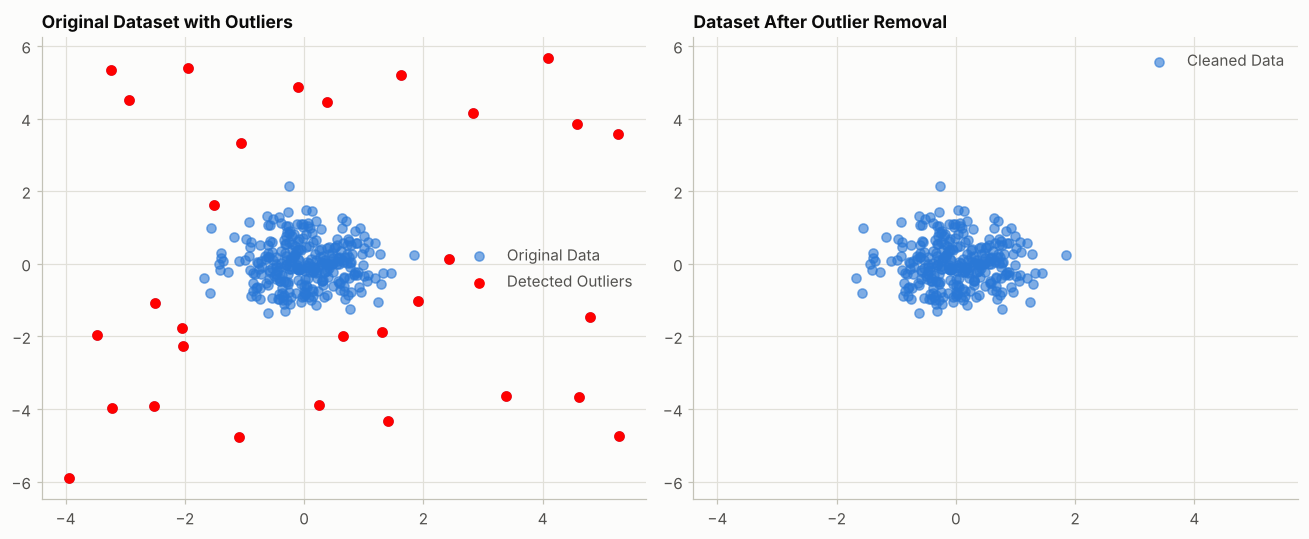

In [40]:
# BOOK CODE (pp. 304-305): remove, replace and cap the outliers, then visualize the original and the cleaned data
# Remove outliers from the dataset
X_cleaned = X[~outlier_mask]

# Replace outliers with the feature-wise median
X_replaced = X.copy()
median_vals = np.median(X[~outlier_mask], axis=0)
X_replaced[outlier_mask] = median_vals

# Cap outliers to specified bounds (winsorization)
X_df = pd.DataFrame(X, columns=['feature1', 'feature2'])
X_capped = X_df.copy()
for col in X_df.columns:
    lower = X_df[col].quantile(0.05)
    upper = X_df[col].quantile(0.95)
    X_capped[col] = X_df[col].clip(lower=lower, upper=upper)

# Visualize original and cleaned datasets with matched axes
plt.figure(figsize=(12, 5))

ax1 = plt.subplot(1, 2, 1)
ax1.scatter(X[:, 0], X[:, 1], label='Original Data', alpha=0.6)
ax1.scatter(X[outlier_mask][:, 0], X[outlier_mask][:, 1], color='red', label='Detected Outliers')
ax1.set_title('Original Dataset with Outliers')
ax1.legend()
ax1.grid(True)

ax2 = plt.subplot(1, 2, 2)
ax2.scatter(X_cleaned[:, 0], X_cleaned[:, 1], label='Cleaned Data', alpha=0.6)
ax2.set_title('Dataset After Outlier Removal')
ax2.legend()
ax2.grid(True)

ax2.set_xlim(ax1.get_xlim())
ax2.set_ylim(ax1.get_ylim())

plt.tight_layout()
plt.show()

**Output analysis.**

* The first listing prints nothing. Isolation Forest flags 30 points, 9% of 330: **27 planted outliers and 3 normal points** (extra (a) prints it).
* Figure 11.12 shows the data with the detected points in red on the left and, on the right, the 300 remaining points on the same axes: a compact cloud. Three planted outliers remain in it, and three normal points were removed. The strategies `X_replaced` and `X_capped` are computed but not drawn.

### Extra experiments

**(a) The four versions of the data.** The book draws only the original data and the removal. The cell draws all four versions (the replaced and capped data are computed in the listing but never shown) and compares their means, standard deviations and correlation with those of the 300 clean inliers.

flagged by the forest: 30 = 27 planted outliers + 3 normal points



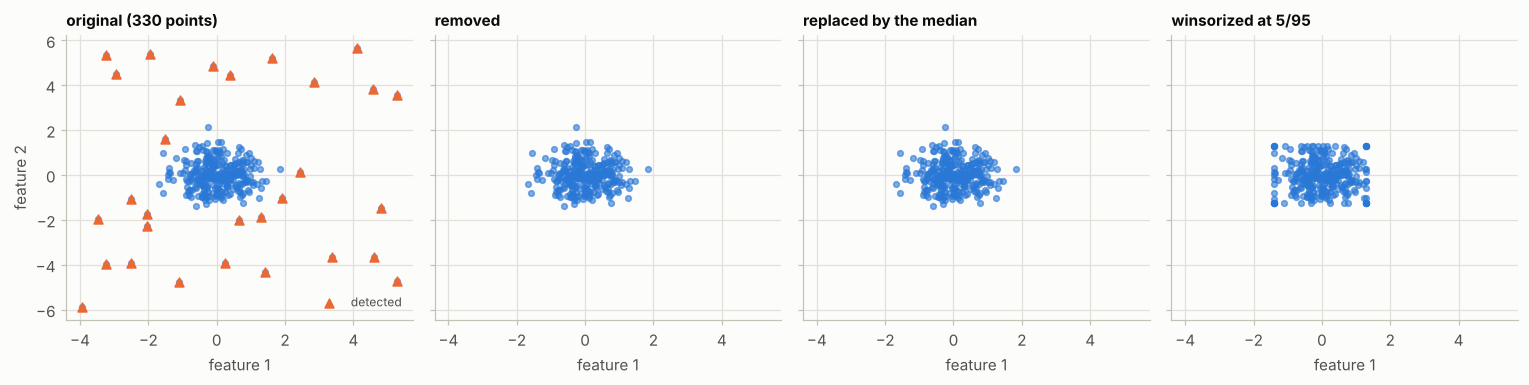

                                   rows  mean f1  mean f2  std f1  std f2  correlation
version                                                                               
original (330 points)               330    0.050    0.004   1.059   1.288        0.066
removed                             300    0.011    0.005   0.607   0.614        0.005
replaced by the median              330    0.009    0.003   0.579   0.585        0.005
winsorized at 5/95                  330    0.010   -0.014   0.678   0.686        0.014
the 300 clean inliers (reference)   300   -0.000   -0.002   0.617   0.637        0.015


In [41]:
# EXTRA (a): all four versions of the data, and their statistics
print(f"flagged by the forest: {outlier_mask.sum()} = {outlier_mask[300:].sum()} planted outliers + {outlier_mask[:300].sum()} normal points\n")
versions = {"original (330 points)": X, "removed": X_cleaned, "replaced by the median": X_replaced, "winsorized at 5/95": X_capped.values}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, (name, data_) in zip(axes, versions.items()):
    ax.scatter(data_[:, 0], data_[:, 1], s=14, color=PALETTE[0], alpha=0.6)
    ax.set_title(f"{name}", fontsize=10)
    ax.set_xlabel("feature 1")
axes[0].scatter(X[outlier_mask][:, 0], X[outlier_mask][:, 1], s=34, color=PALETTE[1], marker="^", label="detected")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("feature 2")
plt.tight_layout()
plt.show()

rows = []
for name, data_ in {**versions, "the 300 clean inliers (reference)": X_inliers}.items():
    rows.append({"version": name, "rows": len(data_), "mean f1": data_[:, 0].mean(), "mean f2": data_[:, 1].mean(),
                 "std f1": data_[:, 0].std(), "std f2": data_[:, 1].std(), "correlation": np.corrcoef(data_.T)[0, 1]})
print(pd.DataFrame(rows).set_index("version").round(3).to_string())

**(b) What does winsorizing touch?** The cell counts the rows changed by the book's 5/95 percentile bounds, by bounds built from the median and three scaled MADs, and by Tukey's fences, on the data with outliers and on the 300 clean inliers alone.

In [42]:
# EXTRA (b): how many rows does each capping rule modify?
def bounds_percentile(data_):
    return np.quantile(data_, 0.05, axis=0), np.quantile(data_, 0.95, axis=0)


def bounds_mad(data_):
    centre = np.median(data_, axis=0)
    scale = np.median(np.abs(data_ - centre), axis=0) * 1.4826
    return centre - 3 * scale, centre + 3 * scale


def bounds_tukey(data_):
    q1, q3 = np.quantile(data_, [0.25, 0.75], axis=0)
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


rows = []
for rule_name, rule in [("5th / 95th percentiles (the book)", bounds_percentile), ("median +- 3 scaled MAD", bounds_mad), ("Tukey's fences (1.5 IQR)", bounds_tukey)]:
    low, high = rule(X)
    changed = (np.clip(X, low, high) != X).any(axis=1)
    low_c, high_c = rule(X_inliers)
    changed_clean = (np.clip(X_inliers, low_c, high_c) != X_inliers).any(axis=1)
    rows.append({
        "rule": rule_name, "rows changed (330 points)": int(changed.sum()), "of them inliers": int(changed[:300].sum()),
        "of them true outliers": int(changed[300:].sum()), "rows changed on the 300 clean inliers": int(changed_clean.sum()),
    })
print(pd.DataFrame(rows).set_index("rule").to_string())
print(f"\nlargest |value| of a true outlier before capping: {np.abs(X_outliers).max():.2f}; of the book's capped data: {np.abs(X_capped.values).max():.2f}")

                                   rows changed (330 points)  of them inliers  of them true outliers  rows changed on the 300 clean inliers
rule                                                                                                                                       
5th / 95th percentiles (the book)                         47               19                     28                                     57
median +- 3 scaled MAD                                    26                1                     25                                      4
Tukey's fences (1.5 IQR)                                  29                3                     26                                      5

largest |value| of a true outlier before capping: 5.89; of the book's capped data: 1.39


**(c) Which strategy for which kind of outlier?** A linear regression $y = 3 x_1 - 2 x_2 + \varepsilon$ is fitted on 300 normal points plus 30 outliers in the features, in two scenarios. In the **errors** scenario the outlier rows are corrupted: their target is random in $[-30, 30]$. In the **genuine** scenario they are real extreme points that obey the same law as the others. Each strategy is judged by the distance between the fitted coefficients and the true ones $(3, -2)$, averaged over 40 repetitions (fewer is better). Isolation Forest detects on the features alone, or on the features and the target.

In [43]:
# EXTRA (c): effect of each handling strategy on the coefficients of a linear regression
from sklearn.linear_model import HuberRegressor, LinearRegression

TRUE_COEF = np.array([3.0, -2.0])


def coefficient_errors(scenario, repeats=40):
    rows = []
    for rep in range(repeats):
        rng = np.random.default_rng(1000 + rep)
        X_in, X_out = rng.normal(0, 0.6, size=(300, 2)), rng.uniform(-6, 6, size=(30, 2))
        y_in = X_in @ TRUE_COEF + rng.normal(0, 0.5, 300)
        y_out = rng.uniform(-30, 30, 30) if scenario == "errors" else X_out @ TRUE_COEF + rng.normal(0, 0.5, 30)
        XX, yy = np.vstack([X_in, X_out]), np.r_[y_in, y_out]
        flag_x = IsolationForest(n_estimators=50, contamination=0.09, random_state=0).fit_predict(XX) == -1
        flag_xy = IsolationForest(n_estimators=50, contamination=0.09, random_state=0).fit_predict(np.c_[XX, yy]) == -1

        def error(features, target):
            return np.linalg.norm(LinearRegression().fit(features, target).coef_ - TRUE_COEF)

        X_med = XX.copy()
        X_med[flag_x] = np.median(XX[~flag_x], axis=0)
        X_cap = np.clip(XX, np.quantile(XX, 0.05, axis=0), np.quantile(XX, 0.95, axis=0))
        y_cap = np.clip(yy, np.quantile(yy, 0.05), np.quantile(yy, 0.95))
        rows.append({
            "keep everything": error(XX, yy),
            "remove the rows flagged on the features": error(XX[~flag_x], yy[~flag_x]),
            "remove the rows flagged on features and target": error(XX[~flag_xy], yy[~flag_xy]),
            "replace the flagged features by the median": error(X_med, yy),
            "winsorize the features at 5/95": error(X_cap, yy),
            "winsorize features and target at 5/95": error(X_cap, y_cap),
            "flag: add an indicator column": np.linalg.norm(LinearRegression().fit(np.c_[XX, flag_x], yy).coef_[:2] - TRUE_COEF),
            "HuberRegressor on everything": np.linalg.norm(HuberRegressor().fit(XX, yy).coef_ - TRUE_COEF),
        })
    frame = pd.DataFrame(rows)
    return frame.mean(), frame.std()


mean_err, sd_err = coefficient_errors("errors")
mean_gen, sd_gen = coefficient_errors("genuine")
result = pd.DataFrame({"errors: mean": mean_err, "errors: sd": sd_err, "genuine: mean": mean_gen, "genuine: sd": sd_gen})
print("distance between the fitted and the true coefficients (40 repetitions; smaller is better)\n")
print(result.round(3).to_string())

distance between the fitted and the true coefficients (40 repetitions; smaller is better)

                                                errors: mean  errors: sd  genuine: mean  genuine: sd
keep everything                                        2.774       0.662          0.030        0.015
remove the rows flagged on the features                0.278       0.202          0.049        0.026
remove the rows flagged on features and target         0.107       0.082          0.052        0.025
replace the flagged features by the median             0.282       0.203          0.055        0.032
winsorize the features at 5/95                         1.242       0.569          1.849        0.370
winsorize features and target at 5/95                  1.092       0.305          0.270        0.116
flag: add an indicator column                          2.731       0.716          0.030        0.016
HuberRegressor on everything                           0.338       0.155          0.033        0.019


**(d) Handling inside a `Pipeline`.** The cell builds a transformer that caps every feature to bounds learned on the training data (`QuantileCapper`), puts it in a pipeline with a linear regression and cross-validates it, printing the bounds learned in each fold. Then it tries a transformer that *drops* the rows flagged by a detector.

In [44]:
# EXTRA (d): capping can be a leak-free pipeline step, removing rows cannot
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline


class QuantileCapper(BaseEstimator, TransformerMixin):
    """Clip every feature to the [q, 1 - q] quantiles learned on the training data."""

    def __init__(self, q=0.05):
        self.q = q

    def fit(self, X, y=None):
        self.low_, self.high_ = np.quantile(X, self.q, axis=0), np.quantile(X, 1 - self.q, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.low_, self.high_)


class DropFlaggedRows(BaseEstimator, TransformerMixin):
    """A transformer that removes the rows an Isolation Forest flags."""

    def fit(self, X, y=None):
        self.detector_ = IsolationForest(random_state=0).fit(X)
        return self

    def transform(self, X):
        return X[self.detector_.predict(X) == 1]


rng = np.random.default_rng(0)
y_demo = X @ TRUE_COEF + rng.normal(0, 0.5, len(X))

pipe = make_pipeline(QuantileCapper(q=0.05), LinearRegression())
cv_result = cross_validate(pipe, X, y_demo, cv=KFold(5, shuffle=True, random_state=0), return_estimator=True)
print("bounds learned by the capper in each of the 5 training folds (lower bound of feature 1, upper bound of feature 1):")
for i, fitted in enumerate(cv_result["estimator"]):
    print(f"  fold {i}: {fitted[0].low_[0]:.3f}, {fitted[0].high_[0]:.3f}")

try:
    make_pipeline(DropFlaggedRows(), LinearRegression()).fit(X, y_demo)
except ValueError as error:
    print(f"\nPipeline with a row-dropping transformer -> ValueError: {error}")

bounds learned by the capper in each of the 5 training folds (lower bound of feature 1, upper bound of feature 1):
  fold 0: -1.396, 1.389
  fold 1: -1.409, 1.178
  fold 2: -1.379, 1.178
  fold 3: -1.387, 1.286
  fold 4: -1.350, 1.286

Pipeline with a row-dropping transformer -> ValueError: Found input variables with inconsistent numbers of samples: [297, 330]


**Analysis of the extras.**

* **(a)** Compared with the 300 clean inliers (standard deviations 0.617 and 0.637), the **removed** data (0.607, 0.614) is the closest. **Replacement** by the median understates the spread (0.579, 0.585) because 30 points sit on the same value. **Winsorizing** overstates it (0.678, 0.686) and the winsorized panel shows why: the values are piled on the edges of a box. Means and correlations are close to the reference in all three.
* **(b)** The book's 5th/95th percentile bounds change **47 rows**: 28 of the 30 outliers (two lie inside the range and are untouched) and **19 normal points**. On the 300 clean inliers alone they still change **57 rows (19%)**: percentile bounds modify a fixed share of every feature, outliers or not. Bounds built from the median and three scaled MADs change 26 rows (25 outliers and 1 inlier; 4 rows on the clean data), and Tukey's fences 29 (26 outliers and 3 inliers; 5 on the clean data). The largest outlier value falls from 5.89 to 1.39, so the capped outliers end up on the rim of the cloud, still extreme in one coordinate.
* **(c)** The best strategy depends on the kind of outlier. **Errors scenario** (corrupted rows): keeping everything gives a coefficient error of 2.774; removing the rows flagged on the features gives 0.278, and 0.107 when the detector also sees the target; replacing the flagged features by the median gives 0.282; `HuberRegressor`, with no detection, 0.338; an indicator column changes nothing (2.731: it only shifts the intercept of the flagged rows). **Genuine scenario** (real extreme points): keeping everything is best (0.030); removal costs accuracy (0.049 and 0.052, about 1.6 to 1.7 times the error) and so does replacement (0.055); Huber matches the best (0.033). **Winsorizing the features alone is the worst strategy with genuine extremes** (1.849 against 0.030 for doing nothing) and a poor one with errors (1.242, half the error of doing nothing but far from the 0.278 of removal), because it shrinks the extreme features and leaves the targets; winsorizing the target too repairs most of it in the genuine scenario (0.270) but not in the errors one (1.092). No strategy wins both, which is why the diagnosis of the next outlier comes before the treatment.
* **(d)** Inside a pipeline the capper learns its own bounds in every training fold (for feature 1: $-1.396$ to $1.389$ in fold 0, $-1.350$ to $1.286$ in fold 4), so the test fold cannot influence them. The transformer that drops flagged rows makes the pipeline fail with `ValueError: Found input variables with inconsistent numbers of samples: [297, 330]`: the transformed matrix has 297 rows and the target 330. Rows have to be removed outside the pipeline, on the training data only.

---
## 7. Choosing the right detection technique

*Book: pp. 306–309.*

### Summary

* **Getting ready** — a `pandas` table that compares the three detectors of the chapter (Figure 11.13). The book says that "this part is really optional".

  | Algorithm | High dimensions | Learns from unlabeled data | New predictions | Large data | Varying densities |
  |---|---|---|---|---|---|
  | Isolation Forest | Yes | Yes | Yes | Yes | No |
  | Local Outlier Factor | No | Yes | No | No | Yes |
  | One-Class SVM | Sometimes | No (novelty only) | Yes | No | Partially |

* **How to do it** — three one-line instantiations: Isolation Forest for large high-dimensional data, `LocalOutlierFactor(n_neighbors=20, contamination=0.1)` for clusters of varying density, `OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)` to train on normal data only.
* **How it works** — Isolation Forest is ideal for general-purpose detection but "may underperform with varying density regions"; LOF finds local deviations but "cannot make predictions on unseen data"; One-Class SVM suits novelty detection, "can be computationally expensive on large datasets and is sensitive to feature scaling". The book's advice: "When in doubt, start with Isolation Forest".
* **There's more** — *hybrid strategies* (combine LOF and Isolation Forest to capture global and local anomalies); *explainability* (the book says Isolation Forest provides feature importance through `feature_importances_()`); *benchmarking* with precision-recall curves, ROC-AUC or domain criteria.
* **Hands-on exercises** — an 8-step workflow: fit the three detectors on the same data, compare them with a confusion matrix, ROC-AUC or a classification report, build a comparison DataFrame, try ensembles.

### Theory

**Questions that decide the choice.**

| Question | Why it matters |
|---|---|
| Is the training data clean? | Clean: novelty detection (`OneClassSVM`, `LocalOutlierFactor(novelty=True)`). Contaminated: outlier detection (Isolation Forest, LOF), or a One-Class SVM with a `nu` that covers the contamination |
| Does the density vary? | A global score (Isolation Forest, One-Class SVM with one `gamma`) compares all points with the same yardstick; LOF compares each point with its own neighbourhood |
| How many samples? | Isolation Forest trains in a time that does not depend on $n$; the One-Class SVM is quadratic or worse; LOF depends on the neighbour search |
| How many features, and how many are informative? | Distances lose contrast as the dimension grows (Beyer et al., 1999); random cuts waste splits on irrelevant features |
| Do the features have the same scale? | LOF and the One-Class SVM use distances; Isolation Forest does not (recipe 2) |
| Is the data roughly Gaussian and unimodal? | Then `EllipticEnvelope` (robust Mahalanobis distance) is a strong baseline |
| Are new points scored later? | `predict` is needed: Isolation Forest, One-Class SVM, LOF with `novelty=True` |

**The complexity of each method.** Isolation Forest: training $O(t\,\psi \log \psi)$ with $\psi = \min(256, n)$ by default (Liu, Ting and Zhou, 2008, 2012), so it does not grow with $n$; scoring is $O(t \log \psi)$ per point. LOF: the cost is that of the $k$-nearest-neighbour search, close to $O(n \log n)$ when the dimension is low and $O(n^2)$ by brute force. One-Class SVM: a kernel matrix, between $O(n^2)$ and $O(n^3)$; scoring costs one kernel evaluation per support vector.

**Combining detectors.** Scores of different detectors are on different scales, so they are combined through their **ranks** (the rank average) or after standardization. The idea of the book's "hybrid strategy" is that one detector covers what the other misses; whether it helps depends on the data, which the extras test.

**How the extras test the table.** Each cell of the book's comparison table is a claim about a *behaviour*. The extras measure the behaviours with the scikit-learn defaults used in the chapter, and report what they find. The results describe these experiments; they are not general laws.

### Book code

In [45]:
# BOOK CODE (p. 307): the comparison table of the three detectors
# Load the libraries
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

# Create a comparison table of methods
data = {
    "Algorithm": ["Isolation Forest", "Local Outlier Factor", "One-Class SVM"],
    "Handles High Dimensions": ["Yes", "No", "Sometimes"],
    "Learns From Unlabeled Data": ["Yes", "Yes", "No (novelty only)"],
    "Supports New Predictions": ["Yes", "No", "Yes"],
    "Scales to Large Data": ["Yes", "No", "No"],
    "Robust to Varying Densities": ["No", "Yes", "Partially"],
    "Main Strength": [
        "Fast, scalable, easy to use",
        "Detects local anomalies in varying densities",
        "Kernel-based boundary modeling"
    ]
}

summary_df = pd.DataFrame(data)
summary_df.set_index("Algorithm", inplace=True)
summary_df

,Handles High Dimensions,Learns From Unlabeled Data,Supports New Predictions,Scales to Large Data,Robust to Varying Densities,Main Strength
Algorithm,,,,,,
Isolation Forest,Yes,Yes,Yes,Yes,No,"Fast, scalable, easy to use"
Local Outlier Factor,No,Yes,No,No,Yes,Detects local anomalies in varying densities
One-Class SVM,Sometimes,No (novelty only),Yes,No,Partially,Kernel-based boundary modeling


In [46]:
# BOOK CODE (p. 308): example-driven decision criteria (the book only instantiates the models)
# If your data is large and high-dimensional, consider:
# Isolation Forest is preferred
model = IsolationForest(contamination=0.1, random_state=2024)

#If your data has clusters with varying densities:
# Local Outlier Factor is better suited
model = LocalOutlierFactor(n_neighbors=20, contamination=0.1)

# If you want to train on only normal data and detect novel data points later:
# One-Class SVM enables novelty detection
model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1)

**Output analysis.**

* The first listing displays the comparison table: three rows, five Yes/No/Sometimes/Partially columns and a "Main Strength" column. The second listing assigns three different models to the same variable `model` and fits none of them; its only content is the three comments, so nothing is printed.
* The table is a set of claims about behaviour, not results of the chapter. The extras test them one by one.

### Extra experiments

The four detectors below use the settings of the chapter: `IsolationForest(random_state=...)`, `LocalOutlierFactor(n_neighbors=20)`, `OneClassSVM(gamma='scale', nu=0.05)` and `EllipticEnvelope(random_state=...)` (a robust-Gaussian baseline, not part of the book's table). Each is scored by the ROC-AUC of its abnormality score against the true labels (1.0 is perfect, 0.5 is chance).

**(a) "Handles high dimensions".** Two designs, each with 300 normal points and 30 outliers, averaged over 3 draws.

* *Few informative features.* Two features carry the anomaly: the normal points are $N(0, 0.6^2)$ and the outliers are uniform in $[-6, 6]^2$ in those two features. The other $d - 2$ features are pure noise $N(0, 1)$ for everybody.
* *All features informative.* Normal points are $N(0, I_d)$, outliers are $N(0, 2.5^2 I_d)$ in *every* feature.

Design: few informative features
                    Isolation Forest    LOF  One-Class SVM  Elliptic Envelope
number of features                                                           
2                              0.967  0.961          0.866              0.964
5                              0.955  0.970          0.924              0.976
10                             0.909  0.964          0.885              0.976
20                             0.828  0.921          0.827              0.954
50                             0.686  0.856          0.767              0.903
100                            0.610  0.824          0.744              0.745
200                            0.612  0.759          0.735              0.571

Design: all features informative
                    Isolation Forest    LOF  One-Class SVM  Elliptic Envelope
number of features                                                           
2                              0.882  0.868          0.608              0.8

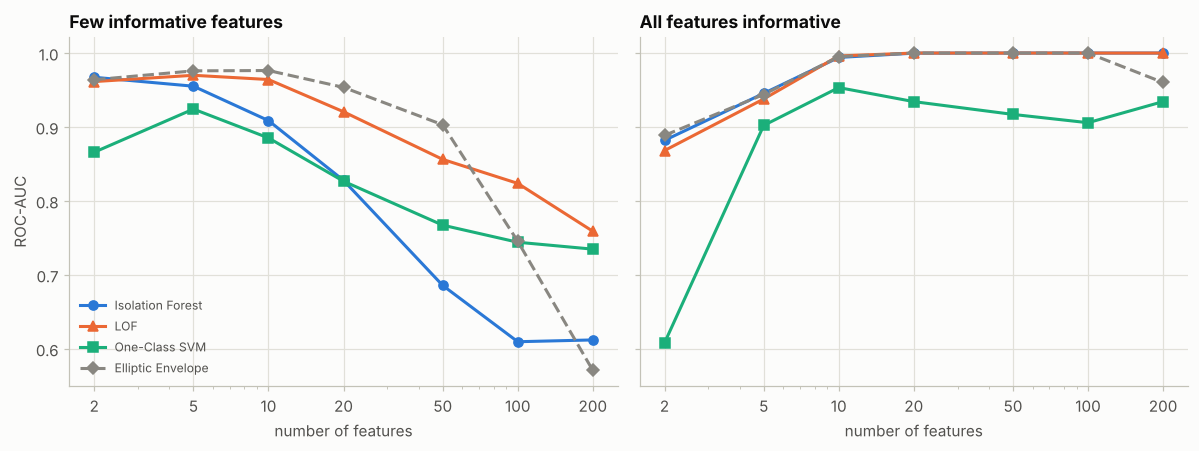

In [47]:
# EXTRA (a): ROC-AUC of four detectors against the number of features, in two designs
DETECTORS = ["Isolation Forest", "LOF", "One-Class SVM", "Elliptic Envelope"]


def abnormality(data_, seed=0):
    """Abnormality scores (higher = more abnormal) of the four detectors, fitted on all the data."""
    return {
        "Isolation Forest": -IsolationForest(random_state=seed).fit(data_).score_samples(data_),
        "LOF": -LocalOutlierFactor(n_neighbors=20).fit(data_).negative_outlier_factor_,
        "One-Class SVM": -QuietOneClassSVM(gamma="scale", nu=0.05).fit(data_).decision_function(data_),
        "Elliptic Envelope": -EllipticEnvelope(random_state=seed).fit(data_).decision_function(data_),
    }


def make_dimension_data(design, d, seed):
    rng = np.random.default_rng(seed)
    if design == "few informative features":
        inliers = np.c_[rng.normal(0, 0.6, (300, 2)), rng.normal(0, 1, (300, d - 2))]
        outliers_ = np.c_[rng.uniform(-6, 6, (30, 2)), rng.normal(0, 1, (30, d - 2))]
    else:
        inliers, outliers_ = rng.normal(0, 1, (300, d)), rng.normal(0, 2.5, (30, d))
    return np.vstack([inliers, outliers_]), np.r_[np.zeros(300), np.ones(30)]


dims = [2, 5, 10, 20, 50, 100, 200]
curves = {}
for design in ["few informative features", "all features informative"]:
    rows = []
    for d in dims:
        aucs = {name: [] for name in DETECTORS}
        for seed in range(3):
            data_, labels = make_dimension_data(design, d, seed)
            for name, s in abnormality(data_, seed).items():
                aucs[name].append(roc_auc_score(labels, s))
        rows.append({"number of features": d, **{name: np.mean(v) for name, v in aucs.items()}})
    curves[design] = pd.DataFrame(rows).set_index("number of features")
    print(f"Design: {design}\n{curves[design].round(3).to_string()}\n")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
styles = {"Isolation Forest": (PALETTE[0], "o", "-"), "LOF": (PALETTE[1], "^", "-"), "One-Class SVM": (PALETTE[2], "s", "-"), "Elliptic Envelope": (MUTED, "D", "--")}
for ax, (design, frame) in zip(axes, curves.items()):
    for name, (colour, marker, ls) in styles.items():
        ax.plot(frame.index, frame[name], color=colour, marker=marker, ls=ls, label=name)
    ax.set_xscale("log")
    ax.set_xticks(dims)
    ax.set_xticklabels([str(d) for d in dims])
    ax.set_xlabel("number of features")
    ax.set_title(design.capitalize())
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

**(b) "Scales to large data".** Fit time plus the time to score the training points, on $n$ points from a 2-D Gaussian (one run each). LOF is also timed with 10 features. The times depend on the machine; the cell reports them, and the analysis only relies on how they *grow*.

seconds (fit + predict on the training points), 2 features unless stated:
       Isolation Forest    LOF  LOF, 10 features  One-Class SVM  Elliptic Envelope
n                                                                                 
1000              0.117  0.005             0.022          0.028              0.460
2000              0.179  0.012             0.117          0.104              0.548
4000              0.146  0.017             0.273          0.550              0.914
8000              0.171  0.034             0.975          2.911              1.818
16000             0.219  0.070             3.404         11.324              3.370

factor by which the time grows when n doubles from 8000 to 16000:
Isolation Forest     1.3
LOF                  2.1
LOF, 10 features     3.5
One-Class SVM        3.9
Elliptic Envelope    1.9


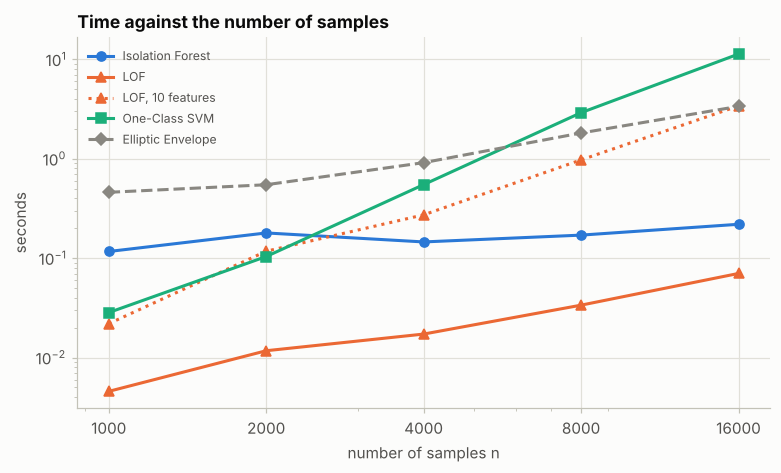

In [48]:
# EXTRA (b): fit time against n (measured on this machine, so the numbers differ from run to run)
import time


def best_time(function, repeats=1):
    best = np.inf
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        best = min(best, time.perf_counter() - start)
    return best


sizes = [1000, 2000, 4000, 8000, 16000]
rows = []
for n in sizes:
    data2 = np.random.default_rng(0).normal(size=(n, 2))
    data10 = np.random.default_rng(0).normal(size=(n, 10))
    rows.append({
        "n": n,
        "Isolation Forest": best_time(lambda: IsolationForest(random_state=0).fit(data2).predict(data2)),
        "LOF": best_time(lambda: LocalOutlierFactor().fit_predict(data2)),
        "LOF, 10 features": best_time(lambda: LocalOutlierFactor().fit_predict(data10)),
        "One-Class SVM": best_time(lambda: QuietOneClassSVM(gamma="scale").fit(data2).predict(data2)),
        "Elliptic Envelope": best_time(lambda: EllipticEnvelope(random_state=0).fit(data2).predict(data2)),
    })
timing = pd.DataFrame(rows).set_index("n")
print("seconds (fit + predict on the training points), 2 features unless stated:")
print(timing.round(3).to_string())
print("\nfactor by which the time grows when n doubles from 8000 to 16000:")
print((timing.loc[16000] / timing.loc[8000]).round(1).to_string())

fig, ax = plt.subplots(figsize=(7.2, 4.4))
timing_styles = {"Isolation Forest": (PALETTE[0], "o", "-"), "LOF": (PALETTE[1], "^", "-"), "LOF, 10 features": (PALETTE[1], "^", ":"), "One-Class SVM": (PALETTE[2], "s", "-"), "Elliptic Envelope": (MUTED, "D", "--")}
for name, (colour, marker, ls) in timing_styles.items():
    ax.plot(timing.index, timing[name], color=colour, marker=marker, ls=ls, label=name)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(sizes)
ax.set_xticklabels([str(n) for n in sizes])
ax.set_xlabel("number of samples n")
ax.set_ylabel("seconds")
ax.set_title("Time against the number of samples")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**(c) "Robust to varying densities", and the hybrid strategy.** The data of recipe 4(c) (a dense cluster, a loose cluster) with three kinds of outliers: 15 *local* outliers on a circle around the dense cluster, 15 *global* outliers far from both clusters, and both together. The table is the mean ROC-AUC over 5 draws. The last two columns average the *ranks* of the scores of Isolation Forest and LOF (the book's hybrid strategy) and of Isolation Forest, LOF and the One-Class SVM.

In [49]:
# EXTRA (c): local, global and mixed outliers, and a rank average of detectors
from scipy.stats import rankdata


def make_scenario(kind, seed):
    rng = np.random.default_rng(seed)
    clusters = np.vstack([rng.normal([0, 0], 0.5, (300, 2)), rng.normal([6, 0], 1.5, (300, 2))])
    local = far = np.empty((0, 2))
    if kind in ("local", "local and global"):
        angle = rng.uniform(0, 2 * np.pi, 15)
        local = 1.8 * np.c_[np.cos(angle), np.sin(angle)]                          # on a circle around the dense cluster
    if kind in ("global", "local and global"):
        candidates = rng.uniform(-6, 12, size=(400, 2))
        keep = (np.linalg.norm(candidates, axis=1) > 3.5) & (np.linalg.norm(candidates - [6, 0], axis=1) > 6.5)
        far = candidates[keep][:15]                                                # far from both clusters
    return np.vstack([clusters, local, far]), np.r_[np.zeros(600), np.ones(len(local) + len(far))]


rows = []
for kind in ["local", "global", "local and global"]:
    aucs = {name: [] for name in DETECTORS + ["rank average IF + LOF", "rank average IF + LOF + OCSVM"]}
    for seed in range(5):
        data_, labels = make_scenario(kind, seed)
        scores = abnormality(data_, seed)
        for name, s in scores.items():
            aucs[name].append(roc_auc_score(labels, s))
        r = {name: rankdata(s) for name, s in scores.items()}
        aucs["rank average IF + LOF"].append(roc_auc_score(labels, r["Isolation Forest"] + r["LOF"]))
        aucs["rank average IF + LOF + OCSVM"].append(roc_auc_score(labels, r["Isolation Forest"] + r["LOF"] + r["One-Class SVM"]))
    rows.append({"outliers": kind, **{name: np.mean(v) for name, v in aucs.items()}})
print(pd.DataFrame(rows).set_index("outliers").round(3).to_string())

                  Isolation Forest    LOF  One-Class SVM  Elliptic Envelope  rank average IF + LOF  rank average IF + LOF + OCSVM
outliers                                                                                                                         
local                        0.923  0.990          0.882               0.50                  0.972                          0.951
global                       1.000  1.000          0.998               0.91                  1.000                          1.000
local and global             0.948  0.995          0.931               0.69                  0.982                          0.976


**(d) "Learns from unlabeled data: No (novelty only)".** The One-Class SVM is trained on 300 clean points, and on the same points plus 30 outliers (9% contamination), always with `nu=0.05`. Both models score a fresh test set of 200 normal points and 50 uniform novelties. Ten repetitions.

In [50]:
# EXTRA (d): One-Class SVM trained on clean data and on contaminated data
rows = []
for seed in range(10):
    rng = np.random.default_rng(seed)
    clean_train = rng.normal(0, 0.6, (300, 2))
    contaminated_train = np.vstack([clean_train, rng.uniform(-6, 6, (30, 2))])
    test_set = np.vstack([rng.normal(0, 0.6, (200, 2)), rng.uniform(-6, 6, (50, 2))])
    labels = np.r_[np.zeros(200), np.ones(50)]
    row = {}
    for name, train_set in [("trained on clean data", clean_train), ("trained on 9% contaminated data", contaminated_train)]:
        fitted = QuietOneClassSVM(gamma="scale", nu=0.05).fit(train_set)
        row[name] = roc_auc_score(labels, -fitted.decision_function(test_set))
    rows.append(row)
print("ROC-AUC on the test set, 10 repetitions:")
print(pd.DataFrame(rows).agg(["mean", "std", "min", "max"]).T.round(3).to_string())

ROC-AUC on the test set, 10 repetitions:
                                  mean    std    min    max
trained on clean data            0.965  0.018  0.942  0.999
trained on 9% contaminated data  0.863  0.046  0.798  0.940


**Analysis of the extras.**

* **(a) High dimensions.** When only 2 of $d$ features are informative, all detectors lose power as noise features are added, and among the three detectors of the book's table Isolation Forest loses the most: its ROC-AUC falls from 0.967 (2 features) to 0.909 (10), 0.686 (50) and **0.61** (0.610 for 100 and 0.612 for 200 features), against 0.824 and 0.759 for LOF and 0.744 and 0.735 for the One-Class SVM. The cause is the random choice of the feature at each cut: with 200 features, 198 of them noise, nearly every cut is wasted. `EllipticEnvelope` is excellent up to 50 features (0.903) and collapses at 200 (0.571), where the covariance of 330 points in 200 dimensions is no longer estimable. When **all** features are informative the picture is the opposite: Isolation Forest and LOF reach 0.994 and 0.996 at 10 features and **1.000** from 20 to 200, and the One-Class SVM stays between 0.90 and 0.95. The book's row ("Isolation Forest: Yes, LOF: No") is **not supported in either design**; what matters is how many features carry the anomaly, not how many there are.
* **(b) Scaling to large data.** From 8,000 to 16,000 points the time of the One-Class SVM is multiplied by about 3 to 5 (it reaches the order of 10 s on the machine that ran this notebook, the largest value of the table), as expected for a kernel method; the time of Isolation Forest hardly changes (its trees see at most 256 points each); `EllipticEnvelope` roughly doubles. LOF depends on the dimension: with 2 features it is the **fastest** detector at every size (0.07 s at 16,000), while with 10 features it takes seconds at 16,000, an order of magnitude more than Isolation Forest. The book's "Scales to large data" is true for Isolation Forest and false for the One-Class SVM; for LOF it depends on the number of features. The times themselves depend on the machine.
* **(c) Varying densities and the hybrid.** With **local** outliers (around the dense cluster) the AUC is **0.990 for LOF**, 0.923 for Isolation Forest, 0.882 for the One-Class SVM and 0.50 for `EllipticEnvelope`, which assumes one Gaussian cloud. With **global** outliers all but `EllipticEnvelope` are near 1 (1.000, 1.000, 0.998). With both kinds, LOF leads (0.995 against 0.948 and 0.931). So the book's row is right *when the anomalies are local*; on its own recipe 4 data, where the outliers are uniform noise, Isolation Forest was better. The rank average of Isolation Forest and LOF gives 0.972, 1.000 and 0.982: better than or equal to Isolation Forest alone, and below LOF alone in two of three cases (equal in the third). It does not beat the best single detector here, but it removes the need to know in advance which kind of anomaly is present.
* **(d) Clean against contaminated training data.** A One-Class SVM trained on clean data reaches an AUC of **0.965** ($\pm$ 0.018); trained on the same data with 9% of outliers added it reaches **0.863** ($\pm$ 0.046). It works without labels in both cases ("learns from unlabeled data: No" is too strong), but it is clearly better when the training data is clean, which is the point of calling it a novelty detector.

---
## 8. Practical exercises in novelty and outlier detection

*Book: pp. 309–310 (the code is in the official `Chapter 11 ... (Exercise Solutions).ipynb`).*

The three exercises give the steps and leave the code to the reader. The cells below are the official solutions, unchanged, run in the book's order so that they continue the global random stream; the extras follow each solution. Two remarks on the official solution notebook: it uses `plt` and `sns` in Exercise 2 without importing them (it only works when run after the main notebook; here the setup cell has imported them), and Exercise 1 is titled "a real-world dataset" ("credit card transaction") but generates synthetic data.

### Exercise 1: Applying Isolation Forest to a real-world dataset

Steps: load the libraries; generate synthetic data with inliers and outliers; scale the data; apply Isolation Forest; evaluate the results; print a classification report as a styled DataFrame.

In [51]:
# BOOK CODE (official solution, Exercise 1)
# Load libraries
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.datasets import make_blobs

# Generate synthetic data with inliers and outliers
X_inliers, _ = make_blobs(n_samples=300, centers=[[0, 0]], cluster_std=0.6, random_state=2024)
X_outliers = np.random.uniform(low=-6, high=6, size=(30, 2))
X = np.vstack([X_inliers, X_outliers])
y_true = np.array([0] * len(X_inliers) + [1] * len(X_outliers))

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply Isolation Forest
model = IsolationForest(contamination=0.09, random_state=2024)
model.fit(X_scaled)
y_pred = model.predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluate the results
print("Exercise 1 Results:")

# Print classification report as a styled DataFrame
report = classification_report(y_true, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

Exercise 1 Results:


,precision,recall,f1-score,support
0,0.993,0.993,0.993,300
1,0.933,0.933,0.933,30
accuracy,0.988,0.988,0.988,1
macro avg,0.963,0.963,0.963,330
weighted avg,0.988,0.988,0.988,330


**Extras for Exercise 1.** (a) The exercise scales the data before the forest. The cell fits the same forest on the *unscaled* data and compares. (b) It adds the threshold-free metrics, with the right orientation of the score.

In [52]:
# EXTRA: Exercise 1 - does the scaling matter, and the threshold-free metrics
unscaled = IsolationForest(contamination=0.09, random_state=2024).fit(X)
print(f"same predictions with and without StandardScaler: {bool((unscaled.predict(X) == model.predict(X_scaled)).all())}")
print(f"confusion matrix (rows: true inlier, true outlier):\n{confusion_matrix(y_true, y_pred_binary)}")
print(f"\nROC-AUC (with -decision_function): {roc_auc_score(y_true, -model.decision_function(X_scaled)):.4f}")
print(f"average precision                : {average_precision_score(y_true, -model.decision_function(X_scaled)):.4f}   (a random detector would get {y_true.mean():.4f})")

same predictions with and without StandardScaler: True
confusion matrix (rows: true inlier, true outlier):
[[298   2]
 [  2  28]]

ROC-AUC (with -decision_function): 0.9683
average precision                : 0.9431   (a random detector would get 0.0909)


### Exercise 2: Using LOF on a network intrusion dataset

Steps: load the libraries; generate clustered data with synthetic noise; scale the data; apply LOF; evaluate the predictions with a confusion matrix and a classification report.


Exercise 2 Results:


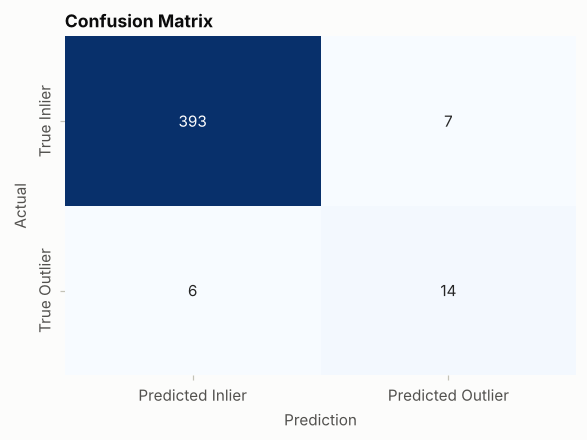

,precision,recall,f1-score,support
0,0.985,0.983,0.984,400
1,0.667,0.700,0.683,20
accuracy,0.969,0.969,0.969,1
macro avg,0.826,0.841,0.833,420
weighted avg,0.970,0.969,0.969,420


In [53]:
# BOOK CODE (official solution, Exercise 2)
# Load libraries
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Generate clustered data with synthetic noise
X_clustered, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)
X_noise = np.random.uniform(low=-6, high=10, size=(20, 2))
X_combined = np.vstack([X_clustered, X_noise])
y_combined = np.array([0] * 400 + [1] * 20)

# Scale the data
X_scaled = scaler.fit_transform(X_combined)

# Apply Local Outlier Factor
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
y_pred = lof.fit_predict(X_scaled)
y_pred_binary = np.where(y_pred == 1, 0, 1)

# Evaluate the predictions
print("\nExercise 2 Results:")
cm = confusion_matrix(y_combined, y_pred_binary)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Inlier', 'Predicted Outlier'],
            yticklabels=['True Inlier', 'True Outlier'])
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

report = classification_report(y_combined, y_pred_binary, output_dict=True)
report = pd.DataFrame(report).transpose()
styled_report = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_report)

**Extras for Exercise 2.** The cell compares LOF on the scaled and on the unscaled data (scaling changes the distances, so it can change the neighbours), over several values of `n_neighbors`, with Isolation Forest on the same data, using the ROC-AUC. It also counts the normal points that were flagged, per cluster, and the planted points inside a cluster.

In [54]:
# EXTRA: Exercise 2 - scaling, n_neighbors and Isolation Forest, by ROC-AUC
rows = []
for k in [5, 10, 20, 50]:
    rows.append({
        "n_neighbors": k,
        "LOF on the scaled data": roc_auc_score(y_combined, -LocalOutlierFactor(n_neighbors=k).fit(X_scaled).negative_outlier_factor_),
        "LOF on the unscaled data": roc_auc_score(y_combined, -LocalOutlierFactor(n_neighbors=k).fit(X_combined).negative_outlier_factor_),
    })
print(pd.DataFrame(rows).set_index("n_neighbors").round(3).to_string())
print(f"\nIsolation Forest on the same data: ROC-AUC {roc_auc_score(y_combined, -IsolationForest(random_state=0).fit(X_combined).score_samples(X_combined)):.3f}")

cluster_of = make_blobs(n_samples=400, centers=[[0, 0], [5, 5]], cluster_std=[0.5, 1.5], random_state=2024)[1]
flagged = y_pred_binary == 1
print(f"\npoints flagged: {flagged.sum()} (true share of outliers {y_combined.mean():.4f}, contamination 0.05 -> {int(np.ceil(0.05 * len(y_combined)))} points)")
print(f"flagged normal points: {flagged[:400][cluster_of == 0].sum()} in the dense cluster, {flagged[:400][cluster_of == 1].sum()} in the loose cluster; true outliers found: {flagged[400:].sum()} of 20")

             LOF on the scaled data  LOF on the unscaled data
n_neighbors                                                  
5                             0.942                     0.943
10                            0.964                     0.963
20                            0.970                     0.970
50                            0.962                     0.962

Isolation Forest on the same data: ROC-AUC 0.965

points flagged: 21 (true share of outliers 0.0476, contamination 0.05 -> 21 points)
flagged normal points: 4 in the dense cluster, 3 in the loose cluster; true outliers found: 14 of 20


### Exercise 3: One-Class SVM for manufacturing sensor data

Steps: load the libraries; generate normal and novel data; fit a One-Class SVM on the normal data; visualize the predictions.

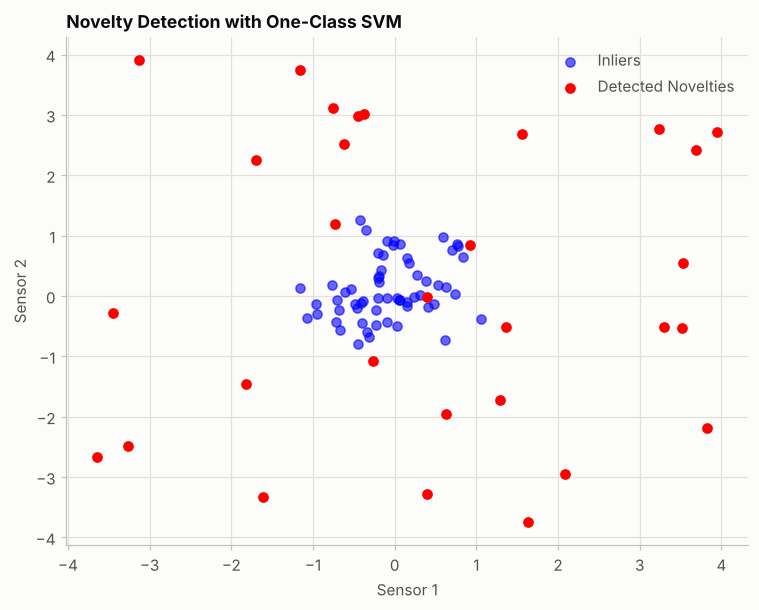

In [55]:
# BOOK CODE (official solution, Exercise 3)
# Load libraries
from sklearn.svm import OneClassSVM
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Generate normal and novel data
X_normal = np.random.normal(loc=0.0, scale=0.5, size=(300, 2))
X_novelty = np.random.uniform(low=-4, high=4, size=(30, 2))
X_train, X_test = train_test_split(X_normal, test_size=0.2, random_state=2024)
X_eval = np.vstack([X_test, X_novelty])

# Fit One-Class SVM on normal data
svm_model = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
svm_model.fit(X_train)
y_pred = svm_model.predict(X_eval)

# Visualize predictions
plt.figure(figsize=(8, 6))
plt.scatter(X_eval[y_pred == 1][:, 0], X_eval[y_pred == 1][:, 1], color='blue', label='Inliers', alpha=0.6)
plt.scatter(X_eval[y_pred == -1][:, 0], X_eval[y_pred == -1][:, 1], color='red', label='Detected Novelties')
plt.title("Novelty Detection with One-Class SVM")
plt.xlabel("Sensor 1")
plt.ylabel("Sensor 2")
plt.legend()
plt.grid(True)
plt.show()

**Extras for Exercise 3.** The solution evaluates only by eye. The cell counts the held-out normal points flagged (false alarms) and the novelties found, notes how many of the 30 "novelties" fall inside the normal cloud, and tabulates both rates for several `nu` and for `gamma` equal to 0.1, 1, 10 and 100 times `gamma='scale'`.

In [56]:
# EXTRA: Exercise 3 - false alarms and detection against nu and gamma
pred = y_pred == -1
n_test = len(X_test)
radius = np.sqrt(chi2.ppf(0.999, 2)) * 0.5
inside = np.linalg.norm(X_novelty, axis=1) < radius
print(f"held-out normal points flagged: {pred[:n_test].sum()} of {n_test}; novelties found: {pred[n_test:].sum()} of {len(X_novelty)}")
print(f"novelties that fall inside the 99.9% disc of the normal cloud (radius {radius:.2f}): {inside.sum()} of {len(X_novelty)}")
print(f"novelties found among the {(~inside).sum()} that are outside the disc: {pred[n_test:][~inside].sum()}\n")

gamma_scale = 1.0 / (X_train.shape[1] * X_train.var())
fresh = np.random.default_rng(0).normal(0, 0.5, size=(5000, 2))
far = np.random.default_rng(1).uniform(-4, 4, size=(8000, 2))
far = far[np.linalg.norm(far, axis=1) > radius]
false_alarm, detection = {}, {}
for nu in [0.01, 0.05, 0.1, 0.2]:
    for factor in [0.1, 1, 10, 100]:
        fitted = QuietOneClassSVM(gamma=factor * gamma_scale, nu=nu).fit(X_train)
        false_alarm[(nu, factor)] = (fitted.predict(fresh) == -1).mean()
        detection[(nu, factor)] = (fitted.predict(far) == -1).mean()
fa = pd.Series(false_alarm).unstack().rename_axis(index="nu", columns="gamma / gamma_scale")
de = pd.Series(detection).unstack().rename_axis(index="nu", columns="gamma / gamma_scale")
print(f"share of 5,000 fresh normal points flagged (gamma_scale = {gamma_scale:.2f}):\n{fa.round(3).to_string()}")
print(f"\nshare of far novelties found:\n{de.round(3).to_string()}")

held-out normal points flagged: 2 of 60; novelties found: 28 of 30
novelties that fall inside the 99.9% disc of the normal cloud (radius 1.86): 5 of 30
novelties found among the 25 that are outside the disc: 25

share of 5,000 fresh normal points flagged (gamma_scale = 1.86):
gamma / gamma_scale  0.1    1.0    10.0   100.0
nu                                             
0.01                 0.011  0.120  0.617  0.901
0.05                 0.056  0.101  0.562  0.903
0.10                 0.116  0.140  0.545  0.901
0.20                 0.203  0.229  0.538  0.901

share of far novelties found:
gamma / gamma_scale  0.1    1.0    10.0   100.0
nu                                             
0.01                 0.992  0.996    1.0    1.0
0.05                 1.000  1.000    1.0    1.0
0.10                 1.000  1.000    1.0    1.0
0.20                 1.000  1.000    1.0    1.0


**Analysis of the exercises.**

* **Exercise 1.** The solution finds 28 of the 30 outliers and flags 2 normal points (confusion matrix $\begin{pmatrix} 298 & 2 \\ 2 & 28 \end{pmatrix}$): precision, recall and F1 of 0.933 for the outliers, 0.993 for the inliers and an accuracy of 0.988. The numbers differ from recipe 5's (0.900) only because the unseeded `np.random.uniform` draws other outliers. The `StandardScaler` of the exercise changes **nothing**: the forest fitted on the unscaled data predicts exactly the same labels. With the right orientation of the score the ROC-AUC is 0.9683 and the average precision 0.9431, against 0.0909 for a random detector.
* **Exercise 2.** LOF flags 21 points (5% of 420; the true share is 20 points, 4.76%): **14 of the 20 outliers and 7 normal points** (4 in the dense cluster, 3 in the loose one), which gives for the outliers a precision of 0.667, a recall of 0.700 and an accuracy of 0.969 overall. By ROC-AUC, LOF with `n_neighbors=20` scores 0.970 on the scaled data and 0.970 on the unscaled data, so scaling is irrelevant here (the two features have similar spreads); Isolation Forest scores 0.965. On this draw of the noise the two detectors are almost equal, whereas on recipe 4's draw of the *same* clusters LOF scored 0.767 and Isolation Forest 0.840: the AUC of a detector, and even the ranking of two detectors, changes with the noise draw, which is another reason to avoid conclusions from one run. `n_neighbors` = 5, 10 and 50 give 0.942, 0.964 and 0.962 on the scaled data.
* **Exercise 3.** The solution flags 2 of the 60 held-out normal points (3%) and 28 of the 30 novelties; 5 of the 30 fall inside the 99.9% disc of the normal cloud, and all 25 outside it are found. At `gamma='scale'` (1.86 here) and `nu=0.05`, 10% of 5,000 fresh normal points are flagged, twice the `nu`, because this `gamma` is much larger than in recipe 3 (0.307) even though the clouds have similar sizes. The cause is the pooled variance: the data here is centred at the origin and its variance is 0.269, whereas in recipe 3 the two features had means of 1.76 and 3.98 and the pooled variance was 1.627. The heuristic `'scale'` therefore depends on where the data sits. The grid confirms that `gamma` is the parameter that matters: the false-alarm rate at `nu=0.05` is 5.6%, 10.1%, 56.2% and 90.3% for 0.1, 1, 10 and 100 times `gamma_scale`, while the far novelties are found in all but two of the sixteen settings at a rate of 1.000 (0.992 and 0.996 in the other two), so the novelties of the exercise cannot tell a good model from a bad one. Only the false alarms on held-out normal data can.

---
## Hands-on exercises of the book, step by step

Every recipe of the chapter closes with a list of steps for the reader. This table records where this notebook performs each of them.

| Recipe | Steps proposed by the book | Where in this notebook |
|---|---|---|
| 1. Introduction | generate data with noise and outliers, visualize, apply `LocalOutlierFactor()` or `IsolationForest()`, plot, change `contamination`, compare LOF, Isolation Forest and One-Class SVM | recipe 1 listings; contamination in extras 1(b) and 2(d); comparison in recipe 7 |
| 2. Isolation Forest | fit, predict, colour the anomalies, change `contamination`, rank with `decision_function()` and plot the scores | recipe 2 listings; extras 2(a), 2(d); the ranking and the maps in extra 2(f) |
| 3. One-Class SVM | training data with normal points only, test data with novelties, `predict`, plot, change `nu` and `gamma`, use `decision_function()` | recipe 3 listings; extras 3(a) to 3(d) |
| 4. LOF | clusters of different densities, `fit_predict`, change `contamination` and `n_neighbors`, observe the LOF score | recipe 4 listings; extras 4(a) to 4(d) |
| 5. Evaluation | labelled data, convert the predictions, confusion matrix, classification report, ROC-AUC from `decision_function()`, other contamination levels | recipe 5 listings; extras 5(a) to 5(g) |
| 6. Handling | inject outliers, detect, remove, replace with the median or mean, cap at 5/95, compare downstream performance, wrap in a `Pipeline` | recipe 6 listings; extras 6(a) to 6(d) |
| 7. Choosing | fit the three detectors on the same data, compare with the confusion matrix, ROC-AUC or classification report, build a comparison table, try ensembles | recipe 7 listings; extras 7(a) to 7(d) |

---
## Choosing a detector: a decision guide

| Situation | Start with | Notes from this chapter |
|---|---|---|
| New observations must be screened, the training data is clean | `OneClassSVM` (standardize first) or `LocalOutlierFactor(novelty=True)` or `IsolationForest` | check that the test "normal" data really comes from the training distribution (recipe 3) |
| Flag the abnormal rows of the training data itself | `IsolationForest` or `LocalOutlierFactor` (default `novelty=False`) | `contamination` flags a fixed share even on clean data |
| Very many samples | `IsolationForest` | the One-Class SVM is quadratic or worse in $n$ |
| Clusters of different density, anomalies that are local | `LocalOutlierFactor` | a global score sees such anomalies less well (Isolation Forest 0.92 against 0.99 for LOF in recipe 7(c)) |
| Anomalies that are global, a handful of informative features | `IsolationForest` or `LocalOutlierFactor` | both reach an AUC near 1 (recipe 7(c)); if most features are noise, LOF held up better (recipe 7(a)) |
| Many features, few of them informative | select features first | every detector loses power as noise features are added |
| Features in different units | standardize for LOF and the One-Class SVM | `IsolationForest` ignores affine rescaling |
| Roughly Gaussian, one cloud | `EllipticEnvelope` as a baseline | strong when the data is one Gaussian cloud (recipe 7(a)), but it fails on several clusters (recipe 7(c)) and when the dimension nears the number of samples; it was the slowest detector at small sizes (recipe 7(b)) |
| No labels | review the top-ranked points, check the stability of the ranking | do not report an F1 you cannot compute |
| Labels available | ROC-AUC and average precision from $-$`decision_function`; precision and recall at the chosen threshold | one run is noisy (recipe 5(f)) |
| Outliers found, what now? | diagnose the cause first; remove errors, keep genuine extremes, prefer robust models over blind cleaning | winsorizing by percentiles changes inliers too (recipe 6) |

---
## Chapter summary

Chapter 11 introduces the three detectors of scikit-learn that most users need. **Isolation Forest** isolates points by random cuts and scores them by path length; **LOF** compares the local density of a point with that of its neighbours; the **One-Class SVM** learns a smooth boundary around the normal data. They share most of their vocabulary (`predict` gives +1 and −1, a higher `decision_function` or `score_samples` means more normal, `contamination` only sets the threshold in Isolation Forest and LOF while the One-Class SVM uses `nu`) and they differ in what they assume and what they cost.

### Key takeaways

1. **Outlier detection looks at the training data; novelty detection assumes clean training data and judges new points.** The estimators and the calls differ.
2. **`contamination` is a decision, not a measurement.** It flags that share of the training points whatever the data, and it only moves the threshold; the ranking is unchanged.
3. **Some planted outliers cannot be found**, because they fall inside the normal cloud. Compare a detector with the oracle ranking before judging it.
4. **Isolation Forest is invariant to affine rescaling of the features;** the One-Class SVM and LOF are not, and `gamma='scale'` uses one global variance.
5. **`nu` is, up to the solver's tolerance, an upper bound on the share of training points flagged and a lower bound on the share of support vectors; `gamma` sets the flexibility of the boundary.** A large `gamma` memorizes the training data and flags new normal data.
6. **For the ROC-AUC, pass $-$`decision_function`.** An AUC near zero means that the sign is inverted.
7. **Accuracy is meaningless for rare outliers; use precision, recall, F1 at a threshold, and ROC-AUC and average precision across thresholds.** A single run is noisy.
8. **Winsorizing by percentiles modifies inliers; removal is right for errors and costs accuracy when the outliers are genuine extremes** (a coefficient error about 1.6 times larger in the experiment).
9. **The choice of detector depends on the density structure, the number of informative features, the sample size and whether new points will be scored.**

### Book vs. library notes

* **ROC-AUC.** The book prints `ROC-AUC Score: 0.0051` for `roc_auc_score(y_true, model.decision_function(X))` and does not comment on it. The score has the wrong orientation; with the sign changed the value is 0.9949.
* **One-Class SVM recipe.** The "normal" test points are generated with `center_box=(0, 1)`, a different centre from the training data (about 5.6 standard deviations away), so the model correctly rejects all of them; the figure's legend also uses red for inliers, the opposite of the other figures. The hyperparameters were not the problem.
* **LOF and new data.** "LOF does not expose a `.predict()` method" and "is not suitable for novelty detection" are true only for the default `novelty=False`. With `novelty=True`, LOF offers `predict`, `decision_function` and `score_samples`.
* **`feature_importances_`.** `IsolationForest` has no such attribute (recipe 7, "There's more").
* **Scaling.** For Isolation Forest, standardizing changes nothing (same trees, same scores); the exercise solutions scale it anyway.
* **The comparison table (recipe 7)** describes tendencies; the measured behaviour depends on the experiment (see the analysis of the extras of recipe 7).
* **Winsorizing** at the 5th and 95th percentiles changes about 10% of the values of every feature, including normal ones.
* **Unseeded draws.** Several listings call `np.random.uniform` with no seed; their numbers depend on the order in which the cells run.
* **`Pipeline` and row removal.** `FunctionTransformer` and `Pipeline` can replace or cap values, but a transformer cannot remove rows.
* **Library version.** All listings and the three official exercise solutions run on scikit-learn 1.9.1.

---
## References

1. Hawkins, D. M. (1980). *Identification of Outliers*. Chapman and Hall.
2. Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: a survey. *ACM Computing Surveys, 41*(3), 15:1–15:58.
3. Aggarwal, C. C. (2017). *Outlier Analysis* (2nd ed.). Springer.
4. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). Isolation Forest. *Proceedings of the 8th IEEE International Conference on Data Mining (ICDM)*, 413–422.
5. Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2012). Isolation-based anomaly detection. *ACM Transactions on Knowledge Discovery from Data, 6*(1), Article 3, 1–39.
6. Hariri, S., Carrasco Kind, M., & Brunner, R. J. (2021). Extended Isolation Forest. *IEEE Transactions on Knowledge and Data Engineering, 33*(4), 1479–1489.
7. Breunig, M. M., Kriegel, H.-P., Ng, R. T., & Sander, J. (2000). LOF: identifying density-based local outliers. *Proceedings of the 2000 ACM SIGMOD International Conference on Management of Data*, 93–104.
8. Schölkopf, B., Platt, J. C., Shawe-Taylor, J., Smola, A. J., & Williamson, R. C. (2001). Estimating the support of a high-dimensional distribution. *Neural Computation, 13*(7), 1443–1471.
9. Tax, D. M. J., & Duin, R. P. W. (2004). Support vector data description. *Machine Learning, 54*(1), 45–66.
10. Rousseeuw, P. J., & Van Driessen, K. (1999). A fast algorithm for the minimum covariance determinant estimator. *Technometrics, 41*(3), 212–223.
11. Iglewicz, B., & Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
12. Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101.
13. Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874.
14. Davis, J., & Goadrich, M. (2006). The relationship between precision-recall and ROC curves. *Proceedings of the 23rd International Conference on Machine Learning (ICML)*, 233–240.
15. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432.
16. Campos, G. O., Zimek, A., Sander, J., Campello, R. J. G. B., Micenková, B., Schubert, E., Assent, I., & Houle, M. E. (2016). On the evaluation of unsupervised outlier detection: measures, datasets, and an empirical study. *Data Mining and Knowledge Discovery, 30*(4), 891–927.
17. Goix, N. (2016). How to evaluate the quality of unsupervised anomaly detection algorithms? arXiv:1607.01152.
18. Beyer, K., Goldstein, J., Ramakrishnan, R., & Shaft, U. (1999). When is "nearest neighbor" meaningful? *Proceedings of the 7th International Conference on Database Theory (ICDT)*, 217–235.
19. scikit-learn documentation: [Novelty and outlier detection](https://scikit-learn.org/stable/modules/outlier_detection.html) · [IsolationForest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html) · [LocalOutlierFactor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html) · [OneClassSVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.OneClassSVM.html) · [Comparing anomaly detection algorithms for outlier detection on toy datasets](https://scikit-learn.org/stable/auto_examples/miscellaneous/plot_anomaly_comparison.html)